In [1]:

import pandas as pd
import numpy as np

# Load Week 3 model evaluation results
results = pd.read_csv(
    "/content/all_seed_test_metrics.csv"
)

print("=== WEEK 4 DATA LOADED ===")
print("Total rows:", len(results))

print("\nColumns:")
print(results.columns.tolist())

print("\nEvaluation splits:")
print(results["Split"].value_counts())

print("\nModels:")
print(results["Model"].unique())

print("\nRandom seeds:")
print(sorted(results["Seed"].unique()))

display(results.head())


=== WEEK 4 DATA LOADED ===
Total rows: 72

Columns:
['Model', 'Group', 'N_pairs', 'RMSE', 'MAE', 'Pearson', 'Split', 'Seed']

Evaluation splits:
Split
cell_blind      36
tissue_blind    36
Name: count, dtype: int64

Models:
['A_baseline' 'B_proteomics' 'C_sex_aware' 'D_full']

Random seeds:
[np.int64(42), np.int64(123), np.int64(456)]


,Model,Group,N_pairs,RMSE,MAE,Pearson,Split,Seed
0,A_baseline,Overall,15501,1.351907,1.019384,0.866900,cell_blind,42
1,A_baseline,Female,6791,1.368149,1.022269,0.866474,cell_blind,42
2,A_baseline,Male,8710,1.339107,1.017134,0.867255,cell_blind,42
3,B_proteomics,Overall,15501,1.341653,1.000253,0.869366,cell_blind,42
4,B_proteomics,Female,6791,1.369433,1.021472,0.866527,cell_blind,42


In [2]:

# WEEK 4 STEP 2: Calculate sex gaps by model and seed

import pandas as pd
import numpy as np

# Keep female and male results
sex_results = results[
    results["Group"].isin(["Female", "Male"])
].copy()

# Put female and male RMSE values side by side
sex_gaps = sex_results.pivot(
    index=["Split", "Seed", "Model"],
    columns="Group",
    values="RMSE"
).reset_index()

# Calculate signed and absolute sex gaps
sex_gaps["Signed_gap"] = (
    sex_gaps["Female"] - sex_gaps["Male"]
)

sex_gaps["Absolute_gap"] = (
    sex_gaps["Signed_gap"].abs()
)

# Sort results
sex_gaps = sex_gaps.sort_values(
    ["Split", "Seed", "Model"]
).reset_index(drop=True)

print("=== SEX GAP BY MODEL AND SEED ===")
display(sex_gaps.round(4))

# Save for later analysis
sex_gaps.to_csv(
    "/content/week4_sex_gaps_by_seed.csv",
    index=False
)

print("\nSaved: week4_sex_gaps_by_seed.csv")
print("Total model runs:", len(sex_gaps))


=== SEX GAP BY MODEL AND SEED ===


Group,Split,Seed,Model,Female,Male,Signed_gap,Absolute_gap
0,cell_blind,42,A_baseline,1.3681,1.3391,0.0290,0.0290
1,cell_blind,42,B_proteomics,1.3694,1.3196,0.0498,0.0498
2,cell_blind,42,C_sex_aware,1.3831,1.3192,0.0639,0.0639
3,cell_blind,42,D_full,1.3754,1.3316,0.0438,0.0438
4,cell_blind,123,A_baseline,1.3894,1.3347,0.0547,0.0547
5,cell_blind,123,B_proteomics,1.3491,1.3215,0.0276,0.0276
6,cell_blind,123,C_sex_aware,1.3712,1.3282,0.0430,0.0430
7,cell_blind,123,D_full,1.3649,1.3512,0.0137,0.0137
8,cell_blind,456,A_baseline,1.3742,1.3153,0.0590,0.0590
9,cell_blind,456,B_proteomics,1.3493,1.3195,0.0298,0.0298



Saved: week4_sex_gaps_by_seed.csv
Total model runs: 24


In [3]:

# WEEK 4 STEP 3: Test H3 across seeds

import pandas as pd
import numpy as np

# Put all four models side by side
h3 = sex_gaps.pivot(
    index=["Split", "Seed"],
    columns="Model",
    values="Absolute_gap"
).reset_index()

# Proteomics effect without sex-aware input
h3["A_to_B_change"] = (
    h3["B_proteomics"] - h3["A_baseline"]
)

# Proteomics effect with sex-aware input
h3["C_to_D_change"] = (
    h3["D_full"] - h3["C_sex_aware"]
)

# Negative values mean smaller sex gaps
h3["AB_gap_shrank"] = h3["A_to_B_change"] < 0
h3["CD_gap_shrank"] = h3["C_to_D_change"] < 0

print("=== H3 EFFECT BY SEED ===")

display(
    h3[[
        "Split",
        "Seed",
        "A_to_B_change",
        "AB_gap_shrank",
        "C_to_D_change",
        "CD_gap_shrank"
    ]].round(4)
)

# Summarize changes across seeds
summary_rows = []

for split in h3["Split"].unique():

    subset = h3[h3["Split"] == split]

    for comparison, column in [
        ("A_to_B", "A_to_B_change"),
        ("C_to_D", "C_to_D_change")
    ]:

        changes = subset[column]

        summary_rows.append({
            "Split": split,
            "Comparison": comparison,
            "Mean_gap_change": changes.mean(),
            "SD_gap_change": changes.std(ddof=1),
            "Seeds_gap_shrank": int((changes < 0).sum()),
            "Total_seeds": len(changes)
        })

h3_summary = pd.DataFrame(summary_rows)

print("\n=== H3 SUMMARY ===")
display(h3_summary.round(4))

# Save results
h3.to_csv(
    "/content/week4_h3_by_seed.csv",
    index=False
)

h3_summary.to_csv(
    "/content/week4_h3_summary.csv",
    index=False
)

print("\nH3 analysis files saved!")


=== H3 EFFECT BY SEED ===


Model,Split,Seed,A_to_B_change,AB_gap_shrank,C_to_D_change,CD_gap_shrank
0,cell_blind,42,0.0208,False,-0.0201,True
1,cell_blind,123,-0.0271,True,-0.0293,True
2,cell_blind,456,-0.0292,True,-0.0058,True
3,tissue_blind,42,-0.0114,True,-0.0138,True
4,tissue_blind,123,0.0167,False,0.0343,False
5,tissue_blind,456,-0.0030,True,-0.0291,True



=== H3 SUMMARY ===


,Split,Comparison,Mean_gap_change,SD_gap_change,Seeds_gap_shrank,Total_seeds
0,cell_blind,A_to_B,-0.0118,0.0283,2,3
1,cell_blind,C_to_D,-0.0184,0.0119,3,3
2,tissue_blind,A_to_B,0.0008,0.0144,2,3
3,tissue_blind,C_to_D,-0.0029,0.0331,2,3



H3 analysis files saved!


In [4]:

# WEEK 4 STEP 4: Extract saved predictions

import zipfile
from pathlib import Path

zip_path = Path(
    "/content/week3_complete_multiseed_results.zip"
)

extract_dir = Path("/content/week4_saved_results")
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path) as z:
    z.extractall(extract_dir)

print("=== PREDICTION FILES FOUND ===")

prediction_files = sorted(
    extract_dir.rglob("*_predictions.csv")
)

print("Total prediction files:", len(prediction_files))

for path in prediction_files:
    print(path.relative_to(extract_dir))


=== PREDICTION FILES FOUND ===
Total prediction files: 24
official_cell_blind/A_baseline_seed123_predictions.csv
official_cell_blind/A_baseline_seed42_predictions.csv
official_cell_blind/A_baseline_seed456_predictions.csv
official_cell_blind/B_proteomics_seed123_predictions.csv
official_cell_blind/B_proteomics_seed42_predictions.csv
official_cell_blind/B_proteomics_seed456_predictions.csv
official_cell_blind/C_sex_aware_seed123_predictions.csv
official_cell_blind/C_sex_aware_seed42_predictions.csv
official_cell_blind/C_sex_aware_seed456_predictions.csv
official_cell_blind/D_full_seed123_predictions.csv
official_cell_blind/D_full_seed42_predictions.csv
official_cell_blind/D_full_seed456_predictions.csv
official_tissue_blind/A_baseline_seed123_predictions.csv
official_tissue_blind/A_baseline_seed42_predictions.csv
official_tissue_blind/A_baseline_seed456_predictions.csv
official_tissue_blind/B_proteomics_seed123_predictions.csv
official_tissue_blind/B_proteomics_seed42_predictions.csv
of

In [5]:

# WEEK 4 STEP 5: Paired cell-line bootstrap for H3
# Uses all three seeds, with identical resamples across seeds

import numpy as np
import pandas as pd
from pathlib import Path

prediction_root = Path("/content/week4_saved_results")

seeds = [42, 123, 456]

comparisons = {
    "A_to_B": ("A_baseline", "B_proteomics"),
    "C_to_D": ("C_sex_aware", "D_full")
}

def load_paired_predictions(split, model_before, model_after):
    folder = prediction_root / f"official_{split}"

    frames = []

    for seed in seeds:
        before = pd.read_csv(
            folder / f"{model_before}_seed{seed}_predictions.csv"
        )

        after = pd.read_csv(
            folder / f"{model_after}_seed{seed}_predictions.csv"
        )

        # Verify prediction rows align
        assert len(before) == len(after)

        assert (
            before[["SIDM", "Drug_ID", "sex"]]
            .reset_index(drop=True)
            .equals(
                after[["SIDM", "Drug_ID", "sex"]]
                .reset_index(drop=True)
            )
        )

        assert np.allclose(
            before["actual"].to_numpy(),
            after["actual"].to_numpy()
        )

        paired = before[
            ["SIDM", "Drug_ID", "sex", "actual"]
        ].copy()

        paired["before"] = before["predicted"].to_numpy()
        paired["after"] = after["predicted"].to_numpy()
        paired["Seed"] = seed

        frames.append(paired)

    return pd.concat(frames, ignore_index=True)


def absolute_sex_gap(df, prediction_column):
    rmse_by_sex = {}

    for sex in ["Female", "Male"]:
        subset = df[df["sex"] == sex]

        rmse_by_sex[sex] = np.sqrt(
            np.mean(
                (
                    subset["actual"]
                    - subset[prediction_column]
                ) ** 2
            )
        )

    return abs(
        rmse_by_sex["Female"] - rmse_by_sex["Male"]
    )


def bootstrap_h3(paired, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)

    # Each SIDM belongs to exactly one sex group
    sex_map = (
        paired[["SIDM", "sex"]]
        .drop_duplicates()
    )

    assert not sex_map["SIDM"].duplicated().any()

    female_ids = sex_map.loc[
        sex_map["sex"] == "Female", "SIDM"
    ].to_numpy()

    male_ids = sex_map.loc[
        sex_map["sex"] == "Male", "SIDM"
    ].to_numpy()

    # Group by cell line and seed, preserving all drug pairs
    grouped = {
        (sidm, s): group
        for (sidm, s), group
        in paired.groupby(["SIDM", "Seed"])
    }

    observed_by_seed = []
    for s in seeds:
        sub = paired[paired["Seed"] == s]
        observed_by_seed.append(
            absolute_sex_gap(sub, "after")
            - absolute_sex_gap(sub, "before")
        )

    observed = float(np.mean(observed_by_seed))
    boot_changes = []

    for _ in range(n_boot):
        female_sample = rng.choice(
            female_ids, size=len(female_ids), replace=True
        )
        male_sample = rng.choice(
            male_ids, size=len(male_ids), replace=True
        )

        # Same resampled cell lines for every seed
        sampled_ids = np.concatenate(
            [female_sample, male_sample]
        )

        seed_changes = []

        for s in seeds:
            boot = pd.concat(
                [grouped[(sidm, s)] for sidm in sampled_ids],
                ignore_index=True
            )

            change = (
                absolute_sex_gap(boot, "after")
                - absolute_sex_gap(boot, "before")
            )

            seed_changes.append(change)

        boot_changes.append(np.mean(seed_changes))

    lower, upper = np.percentile(
        boot_changes, [2.5, 97.5]
    )

    return {
        "Observed_mean_change": observed,
        "CI_lower": lower,
        "CI_upper": upper,
        "CI_includes_zero": lower <= 0 <= upper
    }


h3_bootstrap_rows = []

for split in ["cell_blind", "tissue_blind"]:
    for name, (before, after) in comparisons.items():

        paired = load_paired_predictions(
            split, before, after
        )

        result = bootstrap_h3(
            paired,
            n_boot=1000,
            seed=42
        )

        h3_bootstrap_rows.append({
            "Split": split,
            "Comparison": name,
            **result
        })

h3_bootstrap_results = pd.DataFrame(
    h3_bootstrap_rows
)

print("=== H3 PAIRED BOOTSTRAP RESULTS ===")
display(h3_bootstrap_results.round(4))

h3_bootstrap_results.to_csv(
    "/content/week4_h3_bootstrap_results.csv",
    index=False
)

print("\nSaved: week4_h3_bootstrap_results.csv")


=== H3 PAIRED BOOTSTRAP RESULTS ===


,Split,Comparison,Observed_mean_change,CI_lower,CI_upper,CI_includes_zero
0,cell_blind,A_to_B,-0.0118,-0.0460,0.0218,True
1,cell_blind,C_to_D,-0.0184,-0.0460,0.0470,True
2,tissue_blind,A_to_B,0.0008,-0.0238,0.0221,True
3,tissue_blind,C_to_D,-0.0029,-0.0560,0.0573,True



Saved: week4_h3_bootstrap_results.csv


In [6]:

# WEEK 4 STEP 6: Verify required files

from pathlib import Path

required_files = [
    "week2_aligned_omics_package.zip",
    "GDSC_IC50.csv",
    "multiomics_preprocessing_pipeline.py",
    "Train_Val_Freeze Splits - Celusaurous .xlsx",
    "week3_complete_multiseed_results.zip"
]

print("=== WEEK 4 FILE CHECK ===")

all_found = True

for filename in required_files:
    path = Path("/content") / filename

    if path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")
        all_found = False

print(
    "\nReady for ablation setup:",
    all_found
)


=== WEEK 4 FILE CHECK ===
FOUND: week2_aligned_omics_package.zip
FOUND: GDSC_IC50.csv
FOUND: multiomics_preprocessing_pipeline.py
FOUND: Train_Val_Freeze Splits - Celusaurous .xlsx
FOUND: week3_complete_multiseed_results.zip

Ready for ablation setup: True


In [7]:

# WEEK 4 STEP 7: Extract and inspect Week 2 datasets

from pathlib import Path
import zipfile

zip_path = Path("/content/week2_aligned_omics_package.zip")
extract_dir = Path("/content/week4_data")

extract_dir.mkdir(parents=True, exist_ok=True)

# Extract the aligned molecular datasets
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("=== EXTRACTED WEEK 2 FILES ===")

for path in sorted(extract_dir.rglob("*")):
    if path.is_file():
        print(
            path.relative_to(extract_dir),
            "|",
            round(path.stat().st_size / 1024**2, 2),
            "MB"
        )

print("\nExtraction complete!")


=== EXTRACTED WEEK 2 FILES ===
README.txt | 0.0 MB
XY_gene_module_candidates.csv | 0.0 MB
cnv_aligned.csv | 52.69 MB
expression_aligned.csv | 40.81 MB
mutation_aligned.csv | 3.36 MB
proteomics_aligned.csv | 49.44 MB
sample_metadata.csv | 0.05 MB
sex_labels_matched.csv | 0.13 MB

Extraction complete!


In [8]:

# WEEK 4 STEP 8: Load aligned molecular datasets

import pandas as pd
import numpy as np
from pathlib import Path

data_dir = Path("/content/week4_data")

# Load molecular datasets
expression = pd.read_csv(
    data_dir / "expression_aligned.csv",
    index_col=0
)

mutation = pd.read_csv(
    data_dir / "mutation_aligned.csv",
    index_col=0
)

cnv = pd.read_csv(
    data_dir / "cnv_aligned.csv",
    index_col=0
)

proteomics = pd.read_csv(
    data_dir / "proteomics_aligned.csv",
    index_col=0
)

# Load metadata
sample_metadata = pd.read_csv(
    data_dir / "sample_metadata.csv"
)

sex_metadata = pd.read_csv(
    data_dir / "sex_labels_matched.csv"
)

print("=== MOLECULAR DATASETS LOADED ===")

for name, df in {
    "Expression": expression,
    "Mutation": mutation,
    "CNV": cnv,
    "Proteomics": proteomics
}.items():
    print(f"{name}: {df.shape}")

print("\n=== CELL-LINE ALIGNMENT ===")

reference_ids = expression.index.astype(str).tolist()

for name, df in {
    "Mutation": mutation,
    "CNV": cnv,
    "Proteomics": proteomics
}.items():
    print(
        f"{name} aligned:",
        df.index.astype(str).tolist() == reference_ids
    )

print("\n=== SEX METADATA ===")
print("Rows:", len(sex_metadata))
print("Columns:", sex_metadata.columns.tolist())

display(sex_metadata.head(3))


=== MOLECULAR DATASETS LOADED ===
Expression: (526, 18025)
Mutation: (526, 1667)
CNV: (526, 23264)
Proteomics: (526, 8498)

=== CELL-LINE ALIGNMENT ===
Mutation aligned: True
CNV aligned: True
Proteomics aligned: True

=== SEX METADATA ===
Rows: 526
Columns: ['Cell_line', 'SIDM', 'Project_Identifier', 'Tissue_type', 'Cancer_type', 'Cancer_subtype', 'normalized_name', 'match_key', 'ModelID', 'CellLineName', 'cvcl_final', 'OncotreeLineage', 'reported_sex', 'inferred_sex', 'status', 'review_decision', 'final_sex', 'label_source', 'label_confidence', 'mislabeled', 'recovered', 'uncertain', 'problematic_line', 'exclude_from_sex_analysis', 'xist_score', 'y_score', 'y_cn', 'amelogenin', 'usable_sex', 'high_confidence_usable']


,Cell_line,SIDM,Project_Identifier,Tissue_type,Cancer_type,Cancer_subtype,normalized_name,match_key,ModelID,CellLineName,...,recovered,uncertain,problematic_line,exclude_from_sex_analysis,xist_score,y_score,y_cn,amelogenin,usable_sex,high_confidence_usable
0,L-363,SIDM00312,SIDM00312;L-363,Haematopoietic and Lymphoid,Plasma Cell Myeloma,NaN,L363,L363,ACH-000183,L-363,...,False,True,False,False,0.125176,0.159770,NaN,X,True,False
1,NCI-H727,SIDM01119,SIDM01119;NCI-H727,Lung,Carcinoid Tumour,Lung Carcinoid Tumor,NCIH727,NCIH727,ACH-000775,NCI-H727,...,False,True,False,False,0.204164,0.148290,NaN,X,True,False
2,MV-4-11,SIDM00657,SIDM00657;MV-4-11,Haematopoietic and Lymphoid,Acute Myeloid Leukemia,Acute Monocytic leukemia,MV411,MV411,ACH-000045,MV4-11,...,False,False,False,False,0.113387,4.338635,NaN,"X,Y",True,True


In [10]:


# WEEK 4 STEP 9 FIX: Recreate eligible modeling subset

import pandas as pd

# Load the same drug-response dataset used in Week 3
drug_response = pd.read_csv(
    "/content/GDSC_IC50.csv",
    index_col=0,
    na_values=["NA", ""]
)

# Find cell lines with usable sex labels and valid drug IDs
eligible = sex_metadata[
    (sex_metadata["usable_sex"] == True)
    & (sex_metadata["final_sex"].isin(["Female", "Male"]))
    & (sex_metadata["ModelID"].notna())
    & (sex_metadata["ModelID"].isin(drug_response.columns))
].copy()

# Confirm unique mappings
assert not eligible["SIDM"].duplicated().any()
assert not eligible["ModelID"].duplicated().any()

eligible = eligible.reset_index(drop=True)

# Recreate observed drug-response pairs
matched_responses = drug_response[
    eligible["ModelID"].tolist()
]

response_pairs = (
    matched_responses
    .rename_axis("Drug_ID")
    .reset_index()
    .melt(
        id_vars="Drug_ID",
        var_name="ModelID",
        value_name="response"
    )
    .dropna(subset=["response"])
)

# Add cell-line IDs and sex metadata
response_pairs = response_pairs.merge(
    eligible[
        ["SIDM", "ModelID", "final_sex",
         "label_confidence", "Tissue_type"]
    ],
    on="ModelID",
    how="inner",
    validate="many_to_one"
)

# Validation checks
print("=== WEEK 3 MODELING SUBSET RESTORED ===")
print("Eligible cell lines:", len(eligible))
print("Drug-response observations:", len(response_pairs))

print("\nSex distribution:")
print(eligible["final_sex"].value_counts())

print("\nUnique drugs:")
print(response_pairs["Drug_ID"].nunique())

eligible_ids = set(eligible["SIDM"].astype(str))

for name, matrix in {
    "Expression": expression,
    "Mutation": mutation,
    "CNV": cnv,
    "Proteomics": proteomics
}.items():
    missing = eligible_ids - set(matrix.index.astype(str))
    print(f"{name} missing eligible cells:", len(missing))

assert len(eligible) == 491
assert len(response_pairs) == 106153
assert response_pairs["Drug_ID"].nunique() == 266

print("\nEligible modeling subset verified!")


=== WEEK 3 MODELING SUBSET RESTORED ===
Eligible cell lines: 491
Drug-response observations: 106153

Sex distribution:
final_sex
Male      267
Female    224
Name: count, dtype: int64

Unique drugs:
266
Expression missing eligible cells: 0
Mutation missing eligible cells: 0
CNV missing eligible cells: 0
Proteomics missing eligible cells: 0

Eligible modeling subset verified!


In [11]:

# WEEK 4 STEP 10: Restore official evaluation splits

import pandas as pd

split_file = (
    "/content/Train_Val_Freeze Splits - Celusaurous .xlsx"
)

cell_splits = pd.read_excel(
    split_file,
    sheet_name="cell line splits"
)

tissue_splits = pd.read_excel(
    split_file,
    sheet_name="tissue splits"
)

split_assignments = {}

for name, split_df in [
    ("cell_blind", cell_splits),
    ("tissue_blind", tissue_splits)
]:

    # Map each SIDM to its official partition
    lookup = dict(zip(
        split_df["cell_line_id"].astype(str),
        split_df["split"].astype(str)
    ))

    assigned = response_pairs.copy()

    assigned["split"] = (
        assigned["SIDM"]
        .astype(str)
        .map(lookup)
    )

    # Verify complete coverage
    assert assigned["split"].notna().all()

    # Verify each cell line belongs to one partition
    assert (
        assigned.groupby("SIDM")["split"].nunique() == 1
    ).all()

    split_assignments[name] = assigned

    print(f"\n=== {name.upper()} ===")
    print("Drug-response observations:")
    print(assigned["split"].value_counts())

    print("\nUnique cell lines:")
    print(
        assigned.groupby("split")["SIDM"].nunique()
    )

    if name == "tissue_blind":
        tissue_check = split_df.groupby(
            "tissue"
        )["split"].nunique()

        assert (tissue_check == 1).all()

        print("\nTissue overlap: 0")

print("\nBoth official splits restored successfully!")



=== CELL_BLIND ===
Drug-response observations:
split
train    75028
val      15624
test     15501
Name: count, dtype: int64

Unique cell lines:
split
test      72
train    345
val       74
Name: SIDM, dtype: int64

=== TISSUE_BLIND ===
Drug-response observations:
split
train    74465
test     16256
val      15432
Name: count, dtype: int64

Unique cell lines:
split
test      79
train    338
val       74
Name: SIDM, dtype: int64

Tissue overlap: 0

Both official splits restored successfully!


In [12]:

# WEEK 4 STEP 11: Preprocess molecular features
# separately for each official training split

import numpy as np
from multiomics_preprocessing_pipeline import MultiOmicsPreprocessor

omics_matrices = {
    "expression": expression,
    "mutation": mutation,
    "cnv": cnv,
    "proteomics": proteomics
}

# Preserve the same 491 eligible cell lines
eligible_ids = eligible["SIDM"].astype(str).tolist()

# Store separate preprocessing results
ablation_processors = {}
ablation_omics = {}

for split_name, assigned in split_assignments.items():

    print(f"\n=== {split_name.upper()} PREPROCESSING ===")

    # Get training cell lines for this split
    train_ids = (
        assigned.loc[
            assigned["split"] == "train",
            "SIDM"
        ]
        .astype(str)
        .drop_duplicates()
        .tolist()
    )

    # Create a fresh processor
    processor = MultiOmicsPreprocessor(
        protein_min_coverage=0.70
    )

    # Fit ONLY on official training cells
    processor.fit(
        omics_matrices,
        train_ids
    )

    # Transform the same eligible cell lines
    processed = processor.transform(
        omics_matrices,
        eligible_ids
    )

    ablation_processors[split_name] = processor
    ablation_omics[split_name] = processed

    print("Training cell lines:", len(train_ids))

    for modality, matrix in processed.items():

        values = matrix.to_numpy(dtype=np.float32)

        print(
            f"{modality}: {matrix.shape} | "
            f"All finite: {np.isfinite(values).all()}"
        )

        assert matrix.shape[0] == 491
        assert np.isfinite(values).all()

print("\n=== ALL PREPROCESSING COMPLETE ===")



=== CELL_BLIND PREPROCESSING ===
Training cell lines: 345
expression: (491, 17996) | All finite: True
mutation: (491, 1648) | All finite: True
cnv: (491, 23264) | All finite: True
proteomics: (491, 4153) | All finite: True

=== TISSUE_BLIND PREPROCESSING ===
Training cell lines: 338
expression: (491, 17974) | All finite: True
mutation: (491, 1641) | All finite: True
cnv: (491, 23264) | All finite: True
proteomics: (491, 4162) | All finite: True

=== ALL PREPROCESSING COMPLETE ===


In [13]:

# WEEK 4 STEP 12: Build PyTorch inputs and data loaders

import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Consistent mapping across both splits
cell_ids = eligible["SIDM"].astype(str).tolist()
cell_to_idx = {
    sidm: i for i, sidm in enumerate(cell_ids)
}

drug_ids = sorted(response_pairs["Drug_ID"].unique())
drug_to_idx = {
    drug: i for i, drug in enumerate(drug_ids)
}

class DrugResponseDataset(Dataset):

    def __init__(self, dataframe):
        self.cells = torch.tensor(
            dataframe["cell_idx"].to_numpy(),
            dtype=torch.long
        )
        self.drugs = torch.tensor(
            dataframe["drug_idx"].to_numpy(),
            dtype=torch.long
        )
        self.sexes = torch.tensor(
            dataframe["sex_idx"].to_numpy(),
            dtype=torch.long
        )
        self.targets = torch.tensor(
            dataframe["response"].to_numpy(
                dtype=np.float32
            )
        )

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return (
            self.cells[idx],
            self.drugs[idx],
            self.sexes[idx],
            self.targets[idx]
        )


# Store all split-specific inputs together
ablation_data = {}

for split_name, assigned in split_assignments.items():

    # Build molecular tensors
    tensors = {
        name: torch.tensor(
            ablation_omics[split_name][name]
            .loc[cell_ids]
            .to_numpy(dtype=np.float32)
        ).to(device)
        for name in ablation_omics[split_name]
    }

    # Build response-pair indices
    pairs = assigned.copy()

    pairs["cell_idx"] = (
        pairs["SIDM"].astype(str).map(cell_to_idx)
    )

    pairs["drug_idx"] = (
        pairs["Drug_ID"].map(drug_to_idx)
    )

    pairs["sex_idx"] = (
        pairs["final_sex"].map({
            "Female": 0,
            "Male": 1
        })
    )

    assert pairs[
        ["cell_idx", "drug_idx", "sex_idx"]
    ].notna().all().all()

    loaders = {}

    for partition in ["train", "val", "test"]:

        dataset = DrugResponseDataset(
            pairs[pairs["split"] == partition]
        )

        loaders[partition] = DataLoader(
            dataset,
            batch_size=256,
            shuffle=(partition == "train")
        )

    input_dims = {
        name: tensor.shape[1]
        for name, tensor in tensors.items()
    }

    ablation_data[split_name] = {
        "tensors": tensors,
        "pairs": pairs,
        "loaders": loaders,
        "input_dims": input_dims
    }

    print(f"\n=== {split_name.upper()} ===")
    print("Input dimensions:", input_dims)

    print("Training observations:",
          len(loaders["train"].dataset))
    print("Validation observations:",
          len(loaders["val"].dataset))
    print("Testing observations:",
          len(loaders["test"].dataset))

print("\nDevice:", device)
print("Ablation datasets ready!")



=== CELL_BLIND ===
Input dimensions: {'expression': 17996, 'mutation': 1648, 'cnv': 23264, 'proteomics': 4153}
Training observations: 75028
Validation observations: 15624
Testing observations: 15501

=== TISSUE_BLIND ===
Input dimensions: {'expression': 17974, 'mutation': 1641, 'cnv': 23264, 'proteomics': 4162}
Training observations: 74465
Validation observations: 15432
Testing observations: 16256

Device: cuda
Ablation datasets ready!


In [14]:

# WEEK 4 STEP 13: Flexible attention-fusion architecture

import torch
import torch.nn as nn

class OmicsAblationFusion(nn.Module):

    def __init__(
        self,
        input_dims,
        n_drugs,
        modalities,
        hidden_dim=64,
        use_sex=True
    ):
        super().__init__()

        self.modalities = list(modalities)
        self.use_sex = use_sex

        # Separate encoder for each included modality
        self.encoders = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(input_dims[name], 128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, hidden_dim)
            )
            for name in self.modalities
        })

        # Transformer-based multimodal fusion
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2,
            enable_nested_tensor=False
        )

        # Drug-ID embedding
        self.drug_embedding = nn.Embedding(
            n_drugs,
            hidden_dim
        )

        # Optional biological sex embedding
        if use_sex:
            self.sex_embedding = nn.Embedding(
                2,
                hidden_dim
            )

        prediction_dim = hidden_dim * (
            3 if use_sex else 2
        )

        # Drug-response predictor
        self.predictor = nn.Sequential(
            nn.Linear(prediction_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, omics, drug_ids, sex_ids=None):

        # Encode each available modality
        encoded = [
            self.encoders[name](omics[name])
            for name in self.modalities
        ]

        # Combine molecular representations
        tokens = torch.stack(encoded, dim=1)

        fused = self.transformer(tokens).mean(dim=1)

        # Include drug embedding
        features = [
            fused,
            self.drug_embedding(drug_ids)
        ]

        # Include sex embedding when enabled
        if self.use_sex:
            if sex_ids is None:
                raise ValueError(
                    "Sex IDs required for sex-aware model"
                )

            features.append(
                self.sex_embedding(sex_ids)
            )

        combined = torch.cat(features, dim=1)

        return self.predictor(combined).squeeze(-1)


# Define the three missing ablation configurations
ablation_configs = {
    "no_expression": [
        "mutation", "cnv", "proteomics"
    ],
    "no_mutation": [
        "expression", "cnv", "proteomics"
    ],
    "no_cnv": [
        "expression", "mutation", "proteomics"
    ]
}

# Check all three models with a small batch
test_data = ablation_data["cell_blind"]

for name, modalities in ablation_configs.items():

    model = OmicsAblationFusion(
        input_dims=test_data["input_dims"],
        n_drugs=len(drug_ids),
        modalities=modalities,
        hidden_dim=64,
        use_sex=True
    ).to(device)

    batch_omics = {
        modality: test_data["tensors"][modality][:4]
        for modality in modalities
    }

    batch_drugs = torch.zeros(
        4, dtype=torch.long, device=device
    )

    batch_sexes = torch.zeros(
        4, dtype=torch.long, device=device
    )

    model.eval()

    with torch.no_grad():
        predictions = model(
            batch_omics,
            batch_drugs,
            batch_sexes
        )

    print(f"\n{name}")
    print("Modalities:", modalities)
    print("Prediction shape:", predictions.shape)
    print(
        "All predictions finite:",
        torch.isfinite(predictions).all().item()
    )

    del model

print("\nAll ablation architectures verified!")



no_expression
Modalities: ['mutation', 'cnv', 'proteomics']
Prediction shape: torch.Size([4])
All predictions finite: True

no_mutation
Modalities: ['expression', 'cnv', 'proteomics']
Prediction shape: torch.Size([4])
All predictions finite: True

no_cnv
Modalities: ['expression', 'mutation', 'proteomics']
Prediction shape: torch.Size([4])
All predictions finite: True

All ablation architectures verified!


In [15]:

# WEEK 4 STEP 14: Ablation training function

import torch
import torch.nn as nn
import numpy as np
import random
import copy

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_ablation_model(
    model,
    train_loader,
    val_loader,
    omics_source,
    epochs=15,
    learning_rate=0.001,
    patience=4
):

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()

    best_val_rmse = float("inf")
    best_state = None
    patience_counter = 0
    history = []

    for epoch in range(epochs):

        # TRAINING
        model.train()

        train_squared_error = 0.0
        train_count = 0

        for cells, drugs, sexes, targets in train_loader:

            cells = cells.to(device)
            drugs = drugs.to(device)
            sexes = sexes.to(device)
            targets = targets.to(device)

            batch_omics = {
                name: omics_source[name][cells]
                for name in model.modalities
            }

            optimizer.zero_grad()

            predictions = model(
                batch_omics,
                drugs,
                sexes if model.use_sex else None
            )

            loss = criterion(predictions, targets)

            loss.backward()
            optimizer.step()

            train_squared_error += (
                (predictions.detach() - targets)
                .square()
                .sum()
                .item()
            )

            train_count += len(targets)

        train_rmse = np.sqrt(
            train_squared_error / train_count
        )

        # VALIDATION
        model.eval()

        val_squared_error = 0.0
        val_count = 0

        with torch.no_grad():

            for cells, drugs, sexes, targets in val_loader:

                cells = cells.to(device)
                drugs = drugs.to(device)
                sexes = sexes.to(device)
                targets = targets.to(device)

                batch_omics = {
                    name: omics_source[name][cells]
                    for name in model.modalities
                }

                predictions = model(
                    batch_omics,
                    drugs,
                    sexes if model.use_sex else None
                )

                val_squared_error += (
                    (predictions - targets)
                    .square()
                    .sum()
                    .item()
                )

                val_count += len(targets)

        val_rmse = np.sqrt(
            val_squared_error / val_count
        )

        history.append({
            "epoch": epoch + 1,
            "train_rmse": train_rmse,
            "val_rmse": val_rmse
        })

        print(
            f"Epoch {epoch + 1:02d} | "
            f"Train RMSE: {train_rmse:.4f} | "
            f"Val RMSE: {val_rmse:.4f}"
        )

        # EARLY STOPPING
        if val_rmse < best_val_rmse - 1e-4:

            best_val_rmse = val_rmse

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

            if patience_counter >= patience:
                print("Early stopping triggered.")
                break

    # Restore best validation checkpoint
    model.load_state_dict(best_state)

    return model, history, best_val_rmse


print("=== ABLATION TRAINING FUNCTION READY ===")
print("Device:", device)
print("Configurations:", list(ablation_configs.keys()))
print("Official splits:", list(ablation_data.keys()))


=== ABLATION TRAINING FUNCTION READY ===
Device: cuda
Configurations: ['no_expression', 'no_mutation', 'no_cnv']
Official splits: ['cell_blind', 'tissue_blind']


In [16]:

# WEEK 4 STEP 15: Train No Expression ablation
# Official cell-line-blind split, seed 42

import torch
import pandas as pd
from pathlib import Path

set_seed(42)

# Create a separate directory for Week 4 results
ablation_dir = Path(
    "/content/week4_ablation_results/cell_blind"
)
ablation_dir.mkdir(parents=True, exist_ok=True)

# Get the official cell-line-blind data
experiment = ablation_data["cell_blind"]

# Initialize the ablation model
no_expression_model = OmicsAblationFusion(
    input_dims=experiment["input_dims"],
    n_drugs=len(drug_ids),
    modalities=ablation_configs["no_expression"],
    hidden_dim=64,
    use_sex=True
)

print("=== NO EXPRESSION ABLATION ===")
print("Split: cell_blind")
print("Seed: 42")
print("Modalities:", no_expression_model.modalities)
print("Sex-aware:", no_expression_model.use_sex)

# Train
no_expression_model, no_expression_history, no_expression_val = (
    train_ablation_model(
        model=no_expression_model,
        train_loader=experiment["loaders"]["train"],
        val_loader=experiment["loaders"]["val"],
        omics_source=experiment["tensors"],
        epochs=15,
        learning_rate=0.001,
        patience=4
    )
)

# Save trained model
torch.save(
    no_expression_model.state_dict(),
    ablation_dir / "no_expression_seed42.pt"
)

# Save training history
pd.DataFrame(no_expression_history).to_csv(
    ablation_dir / "no_expression_seed42_history.csv",
    index=False
)

print("\n=== NO EXPRESSION TRAINING COMPLETE ===")
print("Best validation RMSE:", round(no_expression_val, 4))
print("Checkpoint saved successfully!")


=== NO EXPRESSION ABLATION ===
Split: cell_blind
Seed: 42
Modalities: ['mutation', 'cnv', 'proteomics']
Sex-aware: True
Epoch 01 | Train RMSE: 1.8308 | Val RMSE: 1.3859
Epoch 02 | Train RMSE: 1.3077 | Val RMSE: 1.3464
Epoch 03 | Train RMSE: 1.2733 | Val RMSE: 1.3609
Epoch 04 | Train RMSE: 1.2498 | Val RMSE: 1.3444
Epoch 05 | Train RMSE: 1.2281 | Val RMSE: 1.3390
Epoch 06 | Train RMSE: 1.2170 | Val RMSE: 1.3313
Epoch 07 | Train RMSE: 1.2008 | Val RMSE: 1.3474
Epoch 08 | Train RMSE: 1.1895 | Val RMSE: 1.3549
Epoch 09 | Train RMSE: 1.1815 | Val RMSE: 1.3408
Epoch 10 | Train RMSE: 1.1710 | Val RMSE: 1.3245
Epoch 11 | Train RMSE: 1.1700 | Val RMSE: 1.3432
Epoch 12 | Train RMSE: 1.1597 | Val RMSE: 1.3526
Epoch 13 | Train RMSE: 1.1564 | Val RMSE: 1.3474
Epoch 14 | Train RMSE: 1.1519 | Val RMSE: 1.3456
Early stopping triggered.

=== NO EXPRESSION TRAINING COMPLETE ===
Best validation RMSE: 1.3245
Checkpoint saved successfully!


In [17]:

# WEEK 4 STEP 16: Train remaining ablation experiments

import gc
import pandas as pd
import torch
from pathlib import Path

seeds = [42, 123, 456]
training_summary = []

for split_name, experiment in ablation_data.items():

    output_dir = (
        Path("/content/week4_ablation_results")
        / split_name
    )
    output_dir.mkdir(parents=True, exist_ok=True)

    for config_name, modalities in ablation_configs.items():

        for seed in seeds:

            checkpoint_path = (
                output_dir / f"{config_name}_seed{seed}.pt"
            )

            history_path = (
                output_dir / f"{config_name}_seed{seed}_history.csv"
            )

            # Reuse existing completed checkpoints
            if checkpoint_path.exists() and history_path.exists():
                print(
                    f"\nSKIPPING existing: "
                    f"{split_name} | {config_name} | seed {seed}"
                )

                history_df = pd.read_csv(history_path)
                best_val_rmse = history_df["val_rmse"].min()

            else:
                print("\n" + "=" * 55)
                print(
                    f"TRAINING: {split_name} | "
                    f"{config_name} | seed {seed}"
                )
                print("=" * 55)

                set_seed(seed)

                model = OmicsAblationFusion(
                    input_dims=experiment["input_dims"],
                    n_drugs=len(drug_ids),
                    modalities=modalities,
                    hidden_dim=64,
                    use_sex=True
                )

                model, history, best_val_rmse = (
                    train_ablation_model(
                        model=model,
                        train_loader=experiment["loaders"]["train"],
                        val_loader=experiment["loaders"]["val"],
                        omics_source=experiment["tensors"],
                        epochs=15,
                        learning_rate=0.001,
                        patience=4
                    )
                )

                torch.save(
                    model.state_dict(),
                    checkpoint_path
                )

                pd.DataFrame(history).to_csv(
                    history_path,
                    index=False
                )

                del model
                gc.collect()

                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

            training_summary.append({
                "Split": split_name,
                "Ablation": config_name,
                "Seed": seed,
                "Best_val_RMSE": best_val_rmse
            })

            print(
                f"Completed: {split_name} | "
                f"{config_name} | seed {seed} | "
                f"Val RMSE: {best_val_rmse:.4f}"
            )

# Save a combined summary
training_summary_df = pd.DataFrame(training_summary)

training_summary_df.to_csv(
    "/content/week4_ablation_results/"
    "ablation_training_summary.csv",
    index=False
)

print("\n=== ALL ABLATION TRAINING COMPLETE ===")

display(
    training_summary_df.pivot_table(
        index="Ablation",
        columns="Split",
        values="Best_val_RMSE",
        aggfunc=["mean", "std"]
    ).round(4)
)

print("\nTotal models:", len(training_summary_df))



SKIPPING existing: cell_blind | no_expression | seed 42
Completed: cell_blind | no_expression | seed 42 | Val RMSE: 1.3245

TRAINING: cell_blind | no_expression | seed 123
Epoch 01 | Train RMSE: 1.8269 | Val RMSE: 1.4244
Epoch 02 | Train RMSE: 1.3133 | Val RMSE: 1.3443
Epoch 03 | Train RMSE: 1.2720 | Val RMSE: 1.3327
Epoch 04 | Train RMSE: 1.2415 | Val RMSE: 1.3270
Epoch 05 | Train RMSE: 1.2209 | Val RMSE: 1.3437
Epoch 06 | Train RMSE: 1.2068 | Val RMSE: 1.3411
Epoch 07 | Train RMSE: 1.1937 | Val RMSE: 1.3470
Epoch 08 | Train RMSE: 1.1794 | Val RMSE: 1.3525
Early stopping triggered.
Completed: cell_blind | no_expression | seed 123 | Val RMSE: 1.3270

TRAINING: cell_blind | no_expression | seed 456
Epoch 01 | Train RMSE: 1.8370 | Val RMSE: 1.4670
Epoch 02 | Train RMSE: 1.2939 | Val RMSE: 1.3529
Epoch 03 | Train RMSE: 1.2513 | Val RMSE: 1.3853
Epoch 04 | Train RMSE: 1.2230 | Val RMSE: 1.3552
Epoch 05 | Train RMSE: 1.2072 | Val RMSE: 1.3326
Epoch 06 | Train RMSE: 1.1926 | Val RMSE: 1.340

mean                     std             
Split         cell_blind tissue_blind cell_blind tissue_blind
Ablation                                                     
no_cnv            1.2977       1.4002     0.0084       0.0080
no_expression     1.3280       1.3986     0.0041       0.0083
no_mutation       1.2989       1.3972     0.0072       0.0055


Total models: 18


In [18]:

# WEEK 4 STEP 17: Evaluate all ablation models

import torch
import numpy as np
import pandas as pd
from pathlib import Path

evaluation_rows = []

for split_name, experiment in ablation_data.items():

    output_dir = (
        Path("/content/week4_ablation_results")
        / split_name
    )

    # Preserve test observation order
    test_pairs = (
        experiment["pairs"]
        .loc[lambda df: df["split"] == "test"]
        .reset_index(drop=True)
        .copy()
    )

    for config_name, modalities in ablation_configs.items():

        for seed in [42, 123, 456]:

            print(
                f"Evaluating: {split_name} | "
                f"{config_name} | seed {seed}"
            )

            model = OmicsAblationFusion(
                input_dims=experiment["input_dims"],
                n_drugs=len(drug_ids),
                modalities=modalities,
                hidden_dim=64,
                use_sex=True
            ).to(device)

            checkpoint = (
                output_dir / f"{config_name}_seed{seed}.pt"
            )

            model.load_state_dict(
                torch.load(
                    checkpoint,
                    map_location=device,
                    weights_only=True
                )
            )

            model.eval()

            predictions = []
            actuals = []
            sexes = []

            with torch.no_grad():

                for cells, drugs, sex_ids, targets in (
                    experiment["loaders"]["test"]
                ):

                    cells = cells.to(device)
                    drugs = drugs.to(device)
                    sex_ids = sex_ids.to(device)

                    batch_omics = {
                        name: experiment["tensors"][name][cells]
                        for name in model.modalities
                    }

                    outputs = model(
                        batch_omics,
                        drugs,
                        sex_ids
                    )

                    predictions.extend(
                        outputs.cpu().numpy()
                    )

                    actuals.extend(
                        targets.numpy()
                    )

                    sexes.extend(
                        sex_ids.cpu().numpy()
                    )

            predictions = np.array(predictions)
            actuals = np.array(actuals)
            sexes = np.array(sexes)

            # Verify alignment with the saved test rows
            assert len(predictions) == len(test_pairs)
            assert np.allclose(
                actuals,
                test_pairs["response"].to_numpy()
            )

            prediction_df = test_pairs[
                ["SIDM", "Drug_ID", "final_sex"]
            ].copy()

            prediction_df["actual"] = actuals
            prediction_df["predicted"] = predictions

            prediction_df = prediction_df.rename(
                columns={"final_sex": "sex"}
            )

            prediction_df.to_csv(
                output_dir
                / f"{config_name}_seed{seed}_predictions.csv",
                index=False
            )

            # Overall and sex-specific RMSE
            for group, mask in [
                ("All", np.ones(len(sexes), dtype=bool)),
                ("Female", sexes == 0),
                ("Male", sexes == 1)
            ]:

                rmse = np.sqrt(
                    np.mean(
                        (predictions[mask] - actuals[mask]) ** 2
                    )
                )

                evaluation_rows.append({
                    "Split": split_name,
                    "Ablation": config_name,
                    "Seed": seed,
                    "Group": group,
                    "N_pairs": int(mask.sum()),
                    "RMSE": float(rmse)
                })

            del model

# Save all metrics
ablation_metrics = pd.DataFrame(evaluation_rows)

ablation_metrics.to_csv(
    "/content/week4_ablation_results/"
    "ablation_test_metrics.csv",
    index=False
)

# Display overall results
overall_results = (
    ablation_metrics[
        ablation_metrics["Group"] == "All"
    ]
    .groupby(["Split", "Ablation"])["RMSE"]
    .agg(["mean", "std"])
    .round(4)
)

print("\n=== OVERALL TEST PERFORMANCE ===")
display(overall_results)

# Calculate sex gaps
gap_table = (
    ablation_metrics[
        ablation_metrics["Group"].isin(["Female", "Male"])
    ]
    .pivot(
        index=["Split", "Ablation", "Seed"],
        columns="Group",
        values="RMSE"
    )
    .reset_index()
)

gap_table["Absolute_gap"] = (
    gap_table["Female"] - gap_table["Male"]
).abs()

print("\n=== MEAN FEMALE-MALE RMSE GAP ===")

display(
    gap_table.groupby(
        ["Split", "Ablation"]
    )["Absolute_gap"]
    .agg(["mean", "std"])
    .round(4)
)

gap_table.to_csv(
    "/content/week4_ablation_results/"
    "ablation_sex_gaps.csv",
    index=False
)

print("\nAll 18 ablation models evaluated successfully!")


Evaluating: cell_blind | no_expression | seed 42
Evaluating: cell_blind | no_expression | seed 123
Evaluating: cell_blind | no_expression | seed 456
Evaluating: cell_blind | no_mutation | seed 42
Evaluating: cell_blind | no_mutation | seed 123
Evaluating: cell_blind | no_mutation | seed 456
Evaluating: cell_blind | no_cnv | seed 42
Evaluating: cell_blind | no_cnv | seed 123
Evaluating: cell_blind | no_cnv | seed 456
Evaluating: tissue_blind | no_expression | seed 42
Evaluating: tissue_blind | no_expression | seed 123
Evaluating: tissue_blind | no_expression | seed 456
Evaluating: tissue_blind | no_mutation | seed 42
Evaluating: tissue_blind | no_mutation | seed 123
Evaluating: tissue_blind | no_mutation | seed 456
Evaluating: tissue_blind | no_cnv | seed 42
Evaluating: tissue_blind | no_cnv | seed 123
Evaluating: tissue_blind | no_cnv | seed 456

=== OVERALL TEST PERFORMANCE ===


mean     std
Split        Ablation                     
cell_blind   no_cnv         1.3567  0.0091
             no_expression  1.3685  0.0080
             no_mutation    1.3517  0.0085
tissue_blind no_cnv         1.4242  0.0213
             no_expression  1.4312  0.0116
             no_mutation    1.4258  0.0017


=== MEAN FEMALE-MALE RMSE GAP ===


mean     std
Split        Ablation                     
cell_blind   no_cnv         0.0353  0.0026
             no_expression  0.0612  0.0181
             no_mutation    0.0248  0.0077
tissue_blind no_cnv         0.0182  0.0168
             no_expression  0.0226  0.0143
             no_mutation    0.0078  0.0070


All 18 ablation models evaluated successfully!


In [24]:

# WEEK 4 STEP 18: Corrected complete ablation comparison

import pandas as pd
from pathlib import Path

output_dir = Path("/content/week4_ablation_results")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Restore Week 3 full and no-proteomics models
week3 = results[
    results["Model"].isin(["C_sex_aware", "D_full"])
].copy()

week3["Ablation"] = week3["Model"].map({
    "C_sex_aware": "no_proteomics",
    "D_full": "full_model"
})

# 2. Standardize group labels
week3["Group"] = week3["Group"].replace({
    "Overall": "All"
})

week4 = ablation_metrics.copy()

# 3. Combine Week 3 and Week 4 metrics
columns = [
    "Split", "Ablation", "Seed",
    "Group", "N_pairs", "RMSE"
]

combined = pd.concat(
    [week3[columns], week4[columns]],
    ignore_index=True
)

# 4. Check completeness BEFORE calculating differences
expected_ablations = {
    "full_model",
    "no_proteomics",
    "no_expression",
    "no_mutation",
    "no_cnv"
}

assert set(combined["Ablation"]) == expected_ablations
assert set(combined["Group"]) == {"All", "Female", "Male"}

assert not combined.duplicated(
    ["Split", "Ablation", "Seed", "Group"]
).any()

assert len(combined) == 90  # 30 runs x 3 groups

# 5. Extract overall RMSE
overall = (
    combined[combined["Group"] == "All"]
    [["Split", "Ablation", "Seed", "RMSE"]]
    .rename(columns={"RMSE": "Overall_RMSE"})
)

# 6. Extract female and male RMSE
sex_metrics = (
    combined[
        combined["Group"].isin(["Female", "Male"])
    ]
    .pivot(
        index=["Split", "Ablation", "Seed"],
        columns="Group",
        values="RMSE"
    )
    .reset_index()
)

sex_metrics["Absolute_gap"] = (
    sex_metrics["Female"] - sex_metrics["Male"]
).abs()

# 7. Combine overall and sex-specific metrics
comparison = overall.merge(
    sex_metrics,
    on=["Split", "Ablation", "Seed"],
    validate="one_to_one"
)

# 8. Match each model to full Model D from the same seed/split
baseline = (
    comparison[comparison["Ablation"] == "full_model"]
    [["Split", "Seed", "Overall_RMSE", "Absolute_gap"]]
    .rename(columns={
        "Overall_RMSE": "Full_RMSE",
        "Absolute_gap": "Full_gap"
    })
)

comparison = comparison.merge(
    baseline,
    on=["Split", "Seed"],
    validate="many_to_one"
)

# 9. Calculate changes relative to the full model
comparison["RMSE_change"] = (
    comparison["Overall_RMSE"] - comparison["Full_RMSE"]
)

comparison["Gap_change"] = (
    comparison["Absolute_gap"] - comparison["Full_gap"]
)

assert len(comparison) == 30

# 10. Save complete seed-level results
comparison.to_csv(
    output_dir / "complete_ablation_by_seed.csv",
    index=False
)

# 11. Calculate mean results across three seeds
summary = (
    comparison
    .groupby(["Split", "Ablation"])
    .agg(
        Test_RMSE=("Overall_RMSE", "mean"),
        Female_RMSE=("Female", "mean"),
        Male_RMSE=("Male", "mean"),
        Absolute_gap=("Absolute_gap", "mean"),
        RMSE_change=("RMSE_change", "mean"),
        Gap_change=("Gap_change", "mean")
    )
    .reset_index()
    .round(4)
)

summary.to_csv(
    output_dir / "complete_ablation_summary.csv",
    index=False
)

print("=== COMPLETE WEEK 4 ABLATION COMPARISON ===")
display(summary)

print("\nTotal comparisons:", len(comparison))
print("All five configurations verified!")


=== COMPLETE WEEK 4 ABLATION COMPARISON ===


,Split,Ablation,Test_RMSE,Female_RMSE,Male_RMSE,Absolute_gap,RMSE_change,Gap_change
0,cell_blind,full_model,1.3439,1.3618,1.3298,0.0319,0.0000,0.0000
1,cell_blind,no_cnv,1.3567,1.3764,1.3411,0.0353,0.0127,0.0034
2,cell_blind,no_expression,1.3685,1.4025,1.3413,0.0612,0.0245,0.0293
3,cell_blind,no_mutation,1.3517,1.3656,1.3407,0.0248,0.0077,-0.0071
4,cell_blind,no_proteomics,1.3452,1.3732,1.3229,0.0503,0.0013,0.0184
5,tissue_blind,full_model,1.4335,1.4352,1.4282,0.0163,0.0000,0.0000
6,tissue_blind,no_cnv,1.4242,1.4283,1.4120,0.0182,-0.0093,0.0019
7,tissue_blind,no_expression,1.4312,1.4348,1.4204,0.0226,-0.0023,0.0062
8,tissue_blind,no_mutation,1.4258,1.4276,1.4204,0.0078,-0.0077,-0.0086
9,tissue_blind,no_proteomics,1.4465,1.4418,1.4605,0.0192,0.0131,0.0029



Total comparisons: 30
All five configurations verified!


In [20]:

# WEEK 4 STEP 18 FIX: Diagnose model labels

print("=== WEEK 3 MODEL LABELS ===")
print(results["Model"].unique())

print("\n=== WEEK 3 SPLIT LABELS ===")
print(results["Split"].unique())

print("\n=== COMBINED ABLATION LABELS ===")
print(sorted(combined["Ablation"].dropna().unique()))

print("\n=== EXPECTED LABELS MISSING ===")

expected = {
    "full_model",
    "no_expression",
    "no_mutation",
    "no_cnv",
    "no_proteomics"
}

actual = set(combined["Ablation"].dropna())

print("Missing:", expected - actual)
print("Unexpected:", actual - expected)

print("\n=== WEEK 3 ROWS MATCHED ===")
print(week3.groupby(["Split", "Model"]).size())


=== WEEK 3 MODEL LABELS ===
['A_baseline' 'B_proteomics' 'C_sex_aware' 'D_full']

=== WEEK 3 SPLIT LABELS ===
['cell_blind' 'tissue_blind']

=== COMBINED ABLATION LABELS ===
['no_cnv', 'no_expression', 'no_mutation']

=== EXPECTED LABELS MISSING ===
Missing: {'full_model', 'no_proteomics'}
Unexpected: set()

=== WEEK 3 ROWS MATCHED ===
Series([], dtype: int64)


In [23]:

# WEEK 4 STEP 18 FIX #2: Check group labels

print("=== WEEK 3 GROUP LABELS ===")
print(results["Group"].value_counts())

print("\n=== WEEK 4 GROUP LABELS ===")
print(ablation_metrics["Group"].value_counts())

print("\n=== CURRENT COMPARISON ROWS ===")
print("Expected: 30")
print("Actual:", len(comparison))

print("\n=== WEEK 3 MODEL D ROWS ===")
print(
    results[results["Model"] == "D_full"]
    [["Split", "Seed", "Group", "RMSE"]]
    .head(12)
    .to_string(index=False)
)


=== WEEK 3 GROUP LABELS ===
Group
Overall    24
Female     24
Male       24
Name: count, dtype: int64

=== WEEK 4 GROUP LABELS ===
Group
All       18
Female    18
Male      18
Name: count, dtype: int64

=== CURRENT COMPARISON ROWS ===
Expected: 30
Actual: 0

=== WEEK 3 MODEL D ROWS ===
       Split  Seed   Group     RMSE
  cell_blind    42 Overall 1.350921
  cell_blind    42  Female 1.375357
  cell_blind    42    Male 1.331557
  cell_blind   123 Overall 1.357222
  cell_blind   123  Female 1.364908
  cell_blind   123    Male 1.351199
  cell_blind   456 Overall 1.323669
  cell_blind   456  Female 1.345009
  cell_blind   456    Male 1.306789
tissue_blind    42 Overall 1.436874
tissue_blind    42  Female 1.434603
tissue_blind    42    Male 1.443578


In [25]:

# WEEK 4 STEP 19: Check seed consistency

import pandas as pd
import numpy as np

# Exclude the full model because its change is always zero
ablations_only = comparison[
    comparison["Ablation"] != "full_model"
].copy()

# Analyze each modality and official split
consistency = (
    ablations_only
    .groupby(["Split", "Ablation"])
    .agg(
        Mean_RMSE_change=("RMSE_change", "mean"),
        SD_RMSE_change=("RMSE_change", "std"),
        Mean_gap_change=("Gap_change", "mean"),
        SD_gap_change=("Gap_change", "std"),
        Seeds_gap_increased=(
            "Gap_change",
            lambda x: int((x > 0).sum())
        ),
        Seeds_gap_decreased=(
            "Gap_change",
            lambda x: int((x < 0).sum())
        )
    )
    .reset_index()
)

# Save results
consistency.to_csv(
    "/content/week4_ablation_results/"
    "ablation_seed_consistency.csv",
    index=False
)

print("=== ABLATION SEED CONSISTENCY ===")
display(consistency.round(4))

print("\n=== INTERPRETATION ===")
print("Gap increased: removing the modality widened the gap")
print("Gap decreased: removing the modality narrowed the gap")
print("Counts are out of 3 seeds")

print("\nSeed consistency analysis complete!")


=== ABLATION SEED CONSISTENCY ===


,Split,Ablation,Mean_RMSE_change,SD_RMSE_change,Mean_gap_change,SD_gap_change,Seeds_gap_increased,Seeds_gap_decreased
0,cell_blind,no_cnv,0.0127,0.0163,0.0034,0.0185,1,2
1,cell_blind,no_expression,0.0245,0.0255,0.0293,0.0339,3,0
2,cell_blind,no_mutation,0.0077,0.0243,-0.0071,0.0173,1,2
3,cell_blind,no_proteomics,0.0013,0.0142,0.0184,0.0119,3,0
4,tissue_blind,no_cnv,-0.0093,0.0245,0.0019,0.0043,2,1
5,tissue_blind,no_expression,-0.0023,0.0097,0.0062,0.0241,2,1
6,tissue_blind,no_mutation,-0.0077,0.0047,-0.0086,0.0171,1,2
7,tissue_blind,no_proteomics,0.0131,0.0111,0.0029,0.0331,2,1



=== INTERPRETATION ===
Gap increased: removing the modality widened the gap
Gap decreased: removing the modality narrowed the gap
Counts are out of 3 seeds

Seed consistency analysis complete!


In [26]:

# WEEK 4 STEP 20: Verify prediction files for bootstrap

from pathlib import Path
import pandas as pd

week3_dir = Path("/content/week4_saved_results")
week4_dir = Path("/content/week4_ablation_results")

prediction_files = {}

for split in ["cell_blind", "tissue_blind"]:

    for seed in [42, 123, 456]:

        # Week 3 reference models
        for name, original in {
            "full_model": "D_full",
            "no_proteomics": "C_sex_aware"
        }.items():

            path = (
                week3_dir
                / f"official_{split}"
                / f"{original}_seed{seed}_predictions.csv"
            )

            prediction_files[(split, name, seed)] = path

        # New Week 4 ablation models
        for name in [
            "no_expression",
            "no_mutation",
            "no_cnv"
        ]:

            path = (
                week4_dir
                / split
                / f"{name}_seed{seed}_predictions.csv"
            )

            prediction_files[(split, name, seed)] = path

# Check availability
missing = [
    str(path)
    for path in prediction_files.values()
    if not path.exists()
]

print("=== BOOTSTRAP INPUT CHECK ===")
print("Expected prediction files:", 30)
print("Files found:", 30 - len(missing))
print("Missing files:", len(missing))

if missing:
    print("\nMissing paths:")
    for path in missing:
        print(path)
else:
    print("\nAll prediction files found!")

    # Inspect column structures
    for label in [
        ("cell_blind", "full_model", 42),
        ("cell_blind", "no_expression", 42)
    ]:
        df = pd.read_csv(prediction_files[label])
        print(f"\n{label}:")
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print("Unique cell lines:", df["SIDM"].nunique())


=== BOOTSTRAP INPUT CHECK ===
Expected prediction files: 30
Files found: 30
Missing files: 0

All prediction files found!

('cell_blind', 'full_model', 42):
Rows: 15501
Columns: ['actual', 'predicted', 'sex_idx', 'sex', 'SIDM', 'Drug_ID']
Unique cell lines: 72

('cell_blind', 'no_expression', 42):
Rows: 15501
Columns: ['SIDM', 'Drug_ID', 'sex', 'actual', 'predicted']
Unique cell lines: 72


In [27]:

# WEEK 4 STEP 21: Paired cell-line bootstrap

import numpy as np
import pandas as pd

N_BOOT = 1000
SEEDS = [42, 123, 456]
ABLATIONS = [
    "no_expression",
    "no_mutation",
    "no_cnv",
    "no_proteomics"
]

bootstrap_results = []

def load_predictions(split, model, seed):
    df = pd.read_csv(prediction_files[(split, model, seed)])
    return df[["SIDM", "Drug_ID", "sex",
               "actual", "predicted"]].copy()

def prepare_comparison(split, ablation):
    merged_seeds = []

    for seed in SEEDS:
        full = load_predictions(split, "full_model", seed)
        removed = load_predictions(split, ablation, seed)

        keys = ["SIDM", "Drug_ID", "sex"]

        assert not full.duplicated(keys).any()
        assert not removed.duplicated(keys).any()

        paired = full.merge(
            removed,
            on=keys,
            suffixes=("_full", "_ablated"),
            validate="one_to_one"
        )

        assert len(paired) == len(full) == len(removed)
        assert np.allclose(
            paired["actual_full"],
            paired["actual_ablated"]
        )

        paired["Seed"] = seed
        merged_seeds.append(paired)

    return pd.concat(merged_seeds, ignore_index=True)

def absolute_gap(df, prediction_column):
    errors = (
        df[prediction_column] - df["actual_full"]
    ) ** 2

    female_rmse = np.sqrt(
        errors[df["sex"] == "Female"].mean()
    )

    male_rmse = np.sqrt(
        errors[df["sex"] == "Male"].mean()
    )

    return abs(female_rmse - male_rmse)

def bootstrap_comparison(paired, n_boot=1000, seed=42):

    rng = np.random.default_rng(seed)

    # Confirm stable sex labels across seeds
    cell_sex = paired[["SIDM", "sex"]].drop_duplicates()

    assert not cell_sex["SIDM"].duplicated().any()

    female_ids = cell_sex.loc[
        cell_sex["sex"] == "Female", "SIDM"
    ].to_numpy()

    male_ids = cell_sex.loc[
        cell_sex["sex"] == "Male", "SIDM"
    ].to_numpy()

    # Precompute squared-error sums and counts by cell and seed
    squared = paired.copy()
    squared["full_sq"] = (
        squared["predicted_full"] - squared["actual_full"]
    ) ** 2
    squared["ablated_sq"] = (
        squared["predicted_ablated"] - squared["actual_full"]
    ) ** 2

    cell_stats = squared.groupby(
        ["Seed", "SIDM", "sex"]
    ).agg(
        full_ss=("full_sq", "sum"),
        ablated_ss=("ablated_sq", "sum"),
        n=("full_sq", "size")
    ).reset_index()

    # Prepare cell-level arrays in a consistent order
    lookup = {
        (s, sex): (
            cell_stats[
                (cell_stats["Seed"] == s)
                & (cell_stats["sex"] == sex)
            ]
            .set_index("SIDM")
        )
        for s in SEEDS
        for sex in ["Female", "Male"]
    }

    def calculate_change(f_sample, m_sample):

        seed_changes = []

        for s in SEEDS:
            gaps = {}

            for sex, sampled_ids in [
                ("Female", f_sample),
                ("Male", m_sample)
            ]:
                stats = lookup[(s, sex)].loc[sampled_ids]

                total_n = stats["n"].sum()

                gaps[(sex, "full")] = np.sqrt(
                    stats["full_ss"].sum() / total_n
                )

                gaps[(sex, "ablated")] = np.sqrt(
                    stats["ablated_ss"].sum() / total_n
                )

            full_gap = abs(
                gaps[("Female", "full")]
                - gaps[("Male", "full")]
            )

            ablated_gap = abs(
                gaps[("Female", "ablated")]
                - gaps[("Male", "ablated")]
            )

            seed_changes.append(ablated_gap - full_gap)

        return np.mean(seed_changes)

    observed = calculate_change(female_ids, male_ids)

    boot_changes = np.empty(n_boot)

    for b in range(n_boot):
        f_sample = rng.choice(
            female_ids,
            size=len(female_ids),
            replace=True
        )

        m_sample = rng.choice(
            male_ids,
            size=len(male_ids),
            replace=True
        )

        boot_changes[b] = calculate_change(
            f_sample, m_sample
        )

    lower, upper = np.percentile(
        boot_changes, [2.5, 97.5]
    )

    return {
        "Observed_gap_change": observed,
        "CI_lower": lower,
        "CI_upper": upper,
        "CI_includes_zero": bool(lower <= 0 <= upper)
    }

# Run all eight comparisons
for split in ["cell_blind", "tissue_blind"]:
    for ablation in ABLATIONS:

        print(f"Bootstrapping: {split} | {ablation}")

        paired = prepare_comparison(split, ablation)

        outcome = bootstrap_comparison(
            paired, n_boot=N_BOOT, seed=42
        )

        bootstrap_results.append({
            "Split": split,
            "Ablation": ablation,
            **outcome
        })

bootstrap_summary = pd.DataFrame(bootstrap_results)

# Save results
bootstrap_summary.to_csv(
    "/content/week4_ablation_results/"
    "ablation_bootstrap_results.csv",
    index=False
)

print("\n=== ABLATION BOOTSTRAP RESULTS ===")
display(bootstrap_summary.round(4))

print("\nBootstrap analysis complete!")


Bootstrapping: cell_blind | no_expression
Bootstrapping: cell_blind | no_mutation
Bootstrapping: cell_blind | no_cnv
Bootstrapping: cell_blind | no_proteomics
Bootstrapping: tissue_blind | no_expression
Bootstrapping: tissue_blind | no_mutation
Bootstrapping: tissue_blind | no_cnv
Bootstrapping: tissue_blind | no_proteomics

=== ABLATION BOOTSTRAP RESULTS ===


,Split,Ablation,Observed_gap_change,CI_lower,CI_upper,CI_includes_zero
0,cell_blind,no_expression,0.0293,-0.0580,0.1114,True
1,cell_blind,no_mutation,-0.0071,-0.0317,0.0219,True
2,cell_blind,no_cnv,0.0034,-0.0349,0.0342,True
3,cell_blind,no_proteomics,0.0184,-0.0470,0.0460,True
4,tissue_blind,no_expression,0.0062,-0.0393,0.0442,True
5,tissue_blind,no_mutation,-0.0086,-0.0207,0.0181,True
6,tissue_blind,no_cnv,0.0019,-0.0354,0.0325,True
7,tissue_blind,no_proteomics,0.0029,-0.0573,0.0560,True



Bootstrap analysis complete!


In [28]:

# WEEK 4 STEP 22: Inspect attribution setup

import importlib.util
import torch
from pathlib import Path

# Check whether Captum is installed
print("=== CAPTUM AVAILABILITY ===")
print(
    "Captum installed:",
    importlib.util.find_spec("captum") is not None
)

# Locate original Week 3 full-model checkpoint
checkpoint = (
    Path("/content/week4_saved_results")
    / "official_cell_blind"
    / "D_full_seed42.pt"
)

print("\n=== FULL MODEL CHECKPOINT ===")
print("Checkpoint found:", checkpoint.exists())

if checkpoint.exists():
    state = torch.load(
        checkpoint,
        map_location="cpu",
        weights_only=True
    )

    print("Checkpoint entries:", len(state))
    print("\nFirst 12 parameter names:")

    for key in list(state.keys())[:12]:
        print(key)

# Inspect the feature identifiers retained after preprocessing
print("\n=== PROTEOMICS FEATURE IDENTIFIERS ===")

protein_features = (
    ablation_omics["cell_blind"]["proteomics"]
    .columns.tolist()
)

print("Number of retained proteins:", len(protein_features))
print("First 10 identifiers:", protein_features[:10])

print("\n=== ATTRIBUTION SETUP CHECK COMPLETE ===")


=== CAPTUM AVAILABILITY ===
Captum installed: False

=== FULL MODEL CHECKPOINT ===
Checkpoint found: False

=== PROTEOMICS FEATURE IDENTIFIERS ===
Number of retained proteins: 4153
First 10 identifiers: ['P37108;SRP14_HUMAN', 'Q96JP5;ZFP91_HUMAN', 'P36578;RL4_HUMAN', 'Q6SPF0;SAMD1_HUMAN', 'O76031;CLPX_HUMAN', 'Q9BTD8;RBM42_HUMAN', 'Q9P258;RCC2_HUMAN', 'Q8TCS8;PNPT1_HUMAN', 'Q68DK7;MSL1_HUMAN', 'Q96L91;EP400_HUMAN']

=== ATTRIBUTION SETUP CHECK COMPLETE ===


In [29]:

# WEEK 4 STEP 22 FIX: Install Captum and locate checkpoint

%pip -q install captum

from pathlib import Path
import captum

print("=== CAPTUM ===")
print("Captum installed successfully!")

print("\n=== SEARCHING FOR FULL MODEL CHECKPOINTS ===")

# Search extracted Week 3 files
search_dir = Path("/content/week4_saved_results")

checkpoints = sorted(
    p for p in search_dir.rglob("*.pt")
    if "D_full" in p.name
)

for path in checkpoints:
    print(path)

print("\nMatching checkpoints found:", len(checkpoints))

# Inspect the contents of the specific result folder
print("\n=== CELL-LINE-BLIND RESULT FILES ===")

for path in sorted(search_dir.rglob("*")):
    if path.is_file() and "D_full_seed42" in path.name:
        print(path)


=== CAPTUM ===
Captum installed successfully!

=== SEARCHING FOR FULL MODEL CHECKPOINTS ===
/content/week4_saved_results/official_cell_blind/D_full_seed123.pt
/content/week4_saved_results/official_cell_blind/D_full_seed456.pt
/content/week4_saved_results/official_cell_blind/model_D_full_fusion.pt
/content/week4_saved_results/official_tissue_blind/D_full_seed123.pt
/content/week4_saved_results/official_tissue_blind/D_full_seed456.pt
/content/week4_saved_results/official_tissue_blind/model_D_full_fusion.pt

Matching checkpoints found: 6

=== CELL-LINE-BLIND RESULT FILES ===
/content/week4_saved_results/official_cell_blind/D_full_seed42_predictions.csv
/content/week4_saved_results/official_tissue_blind/D_full_seed42_predictions.csv


In [30]:

# WEEK 4 STEP 23: Inspect original Model D checkpoint

import torch
from pathlib import Path

checkpoint_path = Path(
    "/content/week4_saved_results/"
    "official_cell_blind/D_full_seed123.pt"
)

state = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Handle either a direct state dict or a wrapped checkpoint
if isinstance(state, dict) and "model_state_dict" in state:
    state = state["model_state_dict"]

print("=== ORIGINAL MODEL D CHECKPOINT ===")
print("Checkpoint:", checkpoint_path.name)
print("Parameter entries:", len(state))

print("\n=== PARAMETER NAMES AND SHAPES ===")

for name, tensor in state.items():
    print(name, tuple(tensor.shape))

print("\n=== PREPROCESSING DIMENSIONS ===")

for name, dim in ablation_data["cell_blind"]["input_dims"].items():
    print(f"{name}: {dim}")

print("\nCheckpoint inspection complete!")


=== ORIGINAL MODEL D CHECKPOINT ===
Checkpoint: D_full_seed123.pt
Parameter entries: 48

=== PARAMETER NAMES AND SHAPES ===
encoders.expression.0.weight (128, 17996)
encoders.expression.0.bias (128,)
encoders.expression.3.weight (64, 128)
encoders.expression.3.bias (64,)
encoders.mutation.0.weight (128, 1648)
encoders.mutation.0.bias (128,)
encoders.mutation.3.weight (64, 128)
encoders.mutation.3.bias (64,)
encoders.cnv.0.weight (128, 23264)
encoders.cnv.0.bias (128,)
encoders.cnv.3.weight (64, 128)
encoders.cnv.3.bias (64,)
encoders.proteomics.0.weight (128, 4153)
encoders.proteomics.0.bias (128,)
encoders.proteomics.3.weight (64, 128)
encoders.proteomics.3.bias (64,)
transformer.layers.0.self_attn.in_proj_weight (192, 64)
transformer.layers.0.self_attn.in_proj_bias (192,)
transformer.layers.0.self_attn.out_proj.weight (64, 64)
transformer.layers.0.self_attn.out_proj.bias (64,)
transformer.layers.0.linear1.weight (128, 64)
transformer.layers.0.linear1.bias (128,)
transformer.layers.0.

In [31]:

# WEEK 4 STEP 24: Load original full-fusion Model D

import torch
import numpy as np

# Set up the full four-modality architecture
full_modalities = [
    "expression",
    "mutation",
    "cnv",
    "proteomics"
]

experiment = ablation_data["cell_blind"]

full_model = OmicsAblationFusion(
    input_dims=experiment["input_dims"],
    n_drugs=len(drug_ids),
    modalities=full_modalities,
    hidden_dim=64,
    use_sex=True
).to(device)

# Load the original Week 3 checkpoint
full_model.load_state_dict(state, strict=True)
full_model.eval()

print("=== TRAINED MODEL LOADED ===")
print("Split: cell_blind")
print("Seed: 123")
print("Modalities:", full_model.modalities)

# Verify performance on the official test set
predictions = []
actuals = []

with torch.no_grad():
    for cells, drugs, sexes, targets in experiment["loaders"]["test"]:

        cells = cells.to(device)
        drugs = drugs.to(device)
        sexes = sexes.to(device)

        batch_omics = {
            name: experiment["tensors"][name][cells]
            for name in full_model.modalities
        }

        outputs = full_model(
            batch_omics,
            drugs,
            sexes
        )

        predictions.extend(outputs.cpu().numpy())
        actuals.extend(targets.numpy())

rmse = np.sqrt(
    np.mean(
        (np.array(predictions) - np.array(actuals)) ** 2
    )
)

# Compare against saved Week 3 result
expected_rmse = results[
    (results["Model"] == "D_full")
    & (results["Split"] == "cell_blind")
    & (results["Seed"] == 123)
    & (results["Group"] == "Overall")
]["RMSE"].iloc[0]

print("\n=== CHECKPOINT VERIFICATION ===")
print("Recomputed test RMSE:", round(rmse, 6))
print("Saved Week 3 test RMSE:", round(expected_rmse, 6))
print("Absolute difference:", round(abs(rmse - expected_rmse), 8))

assert abs(rmse - expected_rmse) < 1e-4, (
    "Checkpoint predictions do not match Week 3. "
    "Verify architecture, preprocessing, and drug indexing."
)

print("\nCheckpoint verified! Ready for Integrated Gradients.")


=== TRAINED MODEL LOADED ===
Split: cell_blind
Seed: 123
Modalities: ['expression', 'mutation', 'cnv', 'proteomics']

=== CHECKPOINT VERIFICATION ===
Recomputed test RMSE: 1.357222
Saved Week 3 test RMSE: 1.357222
Absolute difference: 0.0

Checkpoint verified! Ready for Integrated Gradients.


In [32]:

# WEEK 4 STEP 25: First protein-level Integrated Gradients

import torch
import numpy as np
import pandas as pd
from captum.attr import IntegratedGradients

full_model.eval()

# Select 32 official test observations
test_loader = ablation_data["cell_blind"]["loaders"]["test"]

cells, drugs, sexes, targets = next(iter(test_loader))

cells = cells[:32].to(device)
drugs = drugs[:32].to(device)
sexes = sexes[:32].to(device)

omics_source = ablation_data["cell_blind"]["tensors"]

# Hold the other three molecular modalities fixed
fixed_omics = {
    name: omics_source[name][cells]
    for name in ["expression", "mutation", "cnv"]
}

# Proteomics is the input being attributed
protein_inputs = (
    omics_source["proteomics"][cells]
    .detach()
    .clone()
)

# Define model output as a function of proteomics
def protein_forward(proteomics_values):

    omics = {
        **fixed_omics,
        "proteomics": proteomics_values
    }

    return full_model(
        omics,
        drugs,
        sexes
    )

# Integrated Gradients
ig = IntegratedGradients(protein_forward)

attributions, convergence_delta = ig.attribute(
    inputs=protein_inputs,
    baselines=torch.zeros_like(protein_inputs),
    n_steps=32,
    internal_batch_size=8,
    return_convergence_delta=True
)

# Convert to NumPy for analysis
protein_attributions = (
    attributions.detach().cpu().numpy()
)

deltas = convergence_delta.detach().cpu().numpy()

print("=== INTEGRATED GRADIENTS RESULTS ===")
print("Observations:", protein_attributions.shape[0])
print("Protein features:", protein_attributions.shape[1])
print("Attributions finite:",
      np.isfinite(protein_attributions).all())

print("\n=== CONVERGENCE CHECK ===")
print("Mean absolute delta:",
      round(np.abs(deltas).mean(), 6))
print("Maximum absolute delta:",
      round(np.abs(deltas).max(), 6))

# Rank proteins by mean absolute attribution
protein_names = (
    ablation_omics["cell_blind"]["proteomics"]
    .columns.tolist()
)

importance = np.abs(protein_attributions).mean(axis=0)

protein_ranking = pd.DataFrame({
    "Protein": protein_names,
    "Mean_absolute_IG": importance
}).sort_values(
    "Mean_absolute_IG",
    ascending=False
).reset_index(drop=True)

print("\n=== TOP 15 ATTRIBUTED PROTEINS ===")
display(protein_ranking.head(15))

# Save pilot results
output_dir = Path("/content/week4_ablation_results")
protein_ranking.to_csv(
    output_dir / "protein_IG_pilot_ranking.csv",
    index=False
)

print("\nProtein attribution pilot complete!")


/usr/local/lib/python3.13/dist-packages/captum/attr/_utils/batching.py:51: UserWarning: Internal batch size cannot be less than the number of input examples. Defaulting to internal batch size of 32 equal to the number of examples.
  warnings.warn(


=== INTEGRATED GRADIENTS RESULTS ===
Observations: 32
Protein features: 4153
Attributions finite: True

=== CONVERGENCE CHECK ===
Mean absolute delta: 0.033009
Maximum absolute delta: 0.114567

=== TOP 15 ATTRIBUTED PROTEINS ===


,Protein,Mean_absolute_IG
0,Q93009;UBP7_HUMAN,0.003646
1,Q15262;PTPRK_HUMAN,0.003052
2,Q13099;IFT88_HUMAN,0.002774
3,Q86XH1;DRC11_HUMAN,0.002620
4,Q16836;HCDH_HUMAN,0.002424
5,Q9UKV5;AMFR_HUMAN,0.002390
6,Q8IWT6;LRC8A_HUMAN,0.002058
7,Q96PU8;QKI_HUMAN,0.002029
8,Q9GZN8;CT027_HUMAN,0.002000
9,Q9Y2R4;DDX52_HUMAN,0.001997



Protein attribution pilot complete!


In [33]:

# WEEK 4 STEP 26: Check IG convergence and ranking stability

import numpy as np
import pandas as pd
import torch
from captum.attr import IntegratedGradients

ig = IntegratedGradients(protein_forward)

step_results = []
rankings = {}

for n_steps in [32, 64, 128]:

    print(f"Calculating IG with {n_steps} steps...")

    attrs, delta = ig.attribute(
        inputs=protein_inputs,
        baselines=torch.zeros_like(protein_inputs),
        n_steps=n_steps,
        internal_batch_size=32,
        return_convergence_delta=True
    )

    attrs_np = attrs.detach().cpu().numpy()
    delta_np = delta.detach().cpu().numpy()

    mean_importance = np.abs(attrs_np).mean(axis=0)

    rankings[n_steps] = pd.Series(
        mean_importance,
        index=protein_names
    )

    step_results.append({
        "Steps": n_steps,
        "Mean_abs_delta": np.abs(delta_np).mean(),
        "Max_abs_delta": np.abs(delta_np).max(),
        "Top_protein": rankings[n_steps].idxmax()
    })

convergence_summary = pd.DataFrame(step_results)

print("\n=== IG CONVERGENCE COMPARISON ===")
display(convergence_summary.round(6))

# Compare top-20 protein rankings
top20_32 = set(rankings[32].nlargest(20).index)
top20_64 = set(rankings[64].nlargest(20).index)
top20_128 = set(rankings[128].nlargest(20).index)

print("\n=== TOP-20 RANKING STABILITY ===")
print("32 vs 64 overlap:", len(top20_32 & top20_64), "/ 20")
print("64 vs 128 overlap:", len(top20_64 & top20_128), "/ 20")
print("32 vs 128 overlap:", len(top20_32 & top20_128), "/ 20")

# Save convergence summary
convergence_summary.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_convergence_check.csv",
    index=False
)

print("\nConvergence check complete!")


Calculating IG with 32 steps...
Calculating IG with 64 steps...
Calculating IG with 128 steps...

=== IG CONVERGENCE COMPARISON ===


,Steps,Mean_abs_delta,Max_abs_delta,Top_protein
0,32,0.033009,0.114567,Q93009;UBP7_HUMAN
1,64,0.037220,0.129331,Q93009;UBP7_HUMAN
2,128,0.030934,0.062807,Q93009;UBP7_HUMAN



=== TOP-20 RANKING STABILITY ===
32 vs 64 overlap: 17 / 20
64 vs 128 overlap: 18 / 20
32 vs 128 overlap: 19 / 20

Convergence check complete!


In [34]:

# WEEK 4 STEP 27: Relative IG convergence check

import torch
import numpy as np
import pandas as pd

full_model.eval()

# Recompute 128-step Integrated Gradients
attrs_128, delta_128 = ig.attribute(
    inputs=protein_inputs,
    baselines=torch.zeros_like(protein_inputs),
    n_steps=128,
    internal_batch_size=32,
    return_convergence_delta=True
)

# Get model predictions at input and baseline
with torch.no_grad():
    actual_predictions = protein_forward(protein_inputs)

    baseline_predictions = protein_forward(
        torch.zeros_like(protein_inputs)
    )

prediction_change = (
    actual_predictions - baseline_predictions
).detach().cpu().numpy()

attribution_sum = (
    attrs_128.sum(dim=1)
    .detach().cpu().numpy()
)

absolute_error = np.abs(
    attribution_sum - prediction_change
)

# Avoid unstable relative errors when prediction change is near zero
relative_error = absolute_error / np.maximum(
    np.abs(prediction_change),
    0.1
)

convergence_details = pd.DataFrame({
    "Prediction_change": prediction_change,
    "Attribution_sum": attribution_sum,
    "Absolute_error": absolute_error,
    "Relative_error": relative_error
})

print("=== RELATIVE IG CONVERGENCE ===")

print(
    "Mean absolute prediction change:",
    round(np.mean(np.abs(prediction_change)), 6)
)

print(
    "Mean absolute attribution error:",
    round(np.mean(absolute_error), 6)
)

print(
    "Median relative error:",
    round(np.median(relative_error), 4)
)

print(
    "Maximum relative error:",
    round(np.max(relative_error), 4)
)

print(
    "Observations with relative error < 10%:",
    int((relative_error < 0.10).sum()),
    "/",
    len(relative_error)
)

print("\n=== FIRST 10 OBSERVATIONS ===")
display(convergence_details.head(10).round(5))

# Save results
convergence_details.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_relative_convergence.csv",
    index=False
)

print("\nRelative convergence analysis complete!")


=== RELATIVE IG CONVERGENCE ===
Mean absolute prediction change: 0.076881
Mean absolute attribution error: 0.030934
Median relative error: 0.2922
Maximum relative error: 0.596
Observations with relative error < 10%: 2 / 32

=== FIRST 10 OBSERVATIONS ===


,Prediction_change,Attribution_sum,Absolute_error,Relative_error
0,0.22894,0.25183,0.02289,0.10000
1,-0.04524,-0.01518,0.03006,0.30058
2,0.01051,-0.02170,0.03221,0.32208
3,0.05520,0.09189,0.03669,0.36691
4,-0.06480,-0.03950,0.02531,0.25305
5,-0.00300,0.01086,0.01386,0.13859
6,0.07269,0.09376,0.02107,0.21072
7,0.19969,0.23597,0.03628,0.18170
8,-0.03420,-0.01719,0.01702,0.17019
9,0.03049,0.01189,0.01860,0.18597



Relative convergence analysis complete!


In [36]:

# WEEK 4 STEP 28 FIX: Correct Captum batch expansion

import numpy as np
import pandas as pd
import torch
from captum.attr import IntegratedGradients

full_model.eval()

# Use the same first 8 observations
small_inputs = protein_inputs[:8].detach()

small_fixed_omics = {
    name: values[:8].detach()
    for name, values in fixed_omics.items()
}

small_drugs = drugs[:8].detach()
small_sexes = sexes[:8].detach()

def small_protein_forward(proteomics_values):

    original_batch = len(small_inputs)
    expanded_batch = len(proteomics_values)

    if expanded_batch % original_batch != 0:
        raise ValueError("Unexpected Captum batch size")

    repeat_factor = expanded_batch // original_batch

    # Captum expands inputs in step-major order
    omics = {
        name: values.repeat(repeat_factor, 1)
        for name, values in small_fixed_omics.items()
    }

    omics["proteomics"] = proteomics_values

    expanded_drugs = small_drugs.repeat(repeat_factor)
    expanded_sexes = small_sexes.repeat(repeat_factor)

    return full_model(
        omics,
        expanded_drugs,
        expanded_sexes
    )

small_ig = IntegratedGradients(small_protein_forward)

diagnostic_rows = []

for steps in [128, 256, 512]:

    print(f"Testing {steps} integration steps...")

    attrs, delta = small_ig.attribute(
        inputs=small_inputs,
        baselines=torch.zeros_like(small_inputs),
        n_steps=steps,
        method="gausslegendre",
        internal_batch_size=32,
        return_convergence_delta=True
    )

    with torch.no_grad():
        prediction_difference = (
            small_protein_forward(small_inputs)
            - small_protein_forward(
                torch.zeros_like(small_inputs)
            )
        )

    attribution_error = torch.abs(
        attrs.sum(dim=1) - prediction_difference
    )

    relative_error = (
        attribution_error
        / prediction_difference.abs().clamp(min=0.1)
    )

    diagnostic_rows.append({
        "Steps": steps,
        "Mean_abs_error": attribution_error.mean().item(),
        "Max_abs_error": attribution_error.max().item(),
        "Median_relative_error": relative_error.median().item(),
        "Below_10_percent": int(
            (relative_error < 0.10).sum().item()
        )
    })

diagnostic = pd.DataFrame(diagnostic_rows)

print("\n=== CORRECTED HIGHER-STEP CONVERGENCE ===")
display(diagnostic.round(5))

diagnostic.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_high_step_diagnostic.csv",
    index=False
)

print("\nCorrected convergence diagnostic complete!")


Testing 128 integration steps...
Testing 256 integration steps...
Testing 512 integration steps...

=== CORRECTED HIGHER-STEP CONVERGENCE ===


,Steps,Mean_abs_error,Max_abs_error,Median_relative_error,Below_10_percent
0,128,0.02730,0.03669,0.21072,0
1,256,0.00904,0.01758,0.02292,4
2,512,0.00983,0.02077,0.05233,4



Corrected convergence diagnostic complete!


In [37]:

# WEEK 4 STEP 29: Final high-step IG convergence check

import numpy as np
import pandas as pd
import torch

print("=== TESTING 1024 INTEGRATION STEPS ===")

attrs_1024, delta_1024 = small_ig.attribute(
    inputs=small_inputs,
    baselines=torch.zeros_like(small_inputs),
    n_steps=1024,
    method="gausslegendre",
    internal_batch_size=8,
    return_convergence_delta=True
)

# Calculate actual change in predictions
with torch.no_grad():
    prediction_change = (
        small_protein_forward(small_inputs)
        - small_protein_forward(
            torch.zeros_like(small_inputs)
        )
    )

# Check IG completeness
attribution_sum = attrs_1024.sum(dim=1)

absolute_error = (
    attribution_sum - prediction_change
).abs()

relative_error = (
    absolute_error
    / prediction_change.abs().clamp(min=0.1)
)

print("\n=== 1024-STEP RESULTS ===")

print(
    "Mean absolute error:",
    round(absolute_error.mean().item(), 6)
)

print(
    "Maximum absolute error:",
    round(absolute_error.max().item(), 6)
)

print(
    "Median relative error:",
    round(relative_error.median().item(), 4)
)

print(
    "Observations below 10% error:",
    int((relative_error < 0.10).sum().item()),
    "/ 8"
)

# Show individual observation results
details_1024 = pd.DataFrame({
    "Prediction_change":
        prediction_change.detach().cpu().numpy(),
    "Attribution_sum":
        attribution_sum.detach().cpu().numpy(),
    "Absolute_error":
        absolute_error.detach().cpu().numpy(),
    "Relative_error":
        relative_error.detach().cpu().numpy()
})

print("\n=== INDIVIDUAL OBSERVATIONS ===")
display(details_1024.round(5))

# Save the diagnostic
details_1024.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_1024_step_diagnostic.csv",
    index=False
)

print("\n1024-step diagnostic complete!")


=== TESTING 1024 INTEGRATION STEPS ===

=== 1024-STEP RESULTS ===
Mean absolute error: 0.009212
Maximum absolute error: 0.019233
Median relative error: 0.0483
Observations below 10% error: 4 / 8

=== INDIVIDUAL OBSERVATIONS ===


,Prediction_change,Attribution_sum,Absolute_error,Relative_error
0,0.22894,0.22862,0.00031,0.00137
1,-0.04524,-0.02855,0.01668,0.16681
2,0.01051,0.00568,0.00483,0.04825
3,0.05520,0.06699,0.01179,0.11786
4,-0.06480,-0.04557,0.01923,0.19233
5,-0.00300,0.01205,0.01505,0.15046
6,0.07269,0.07334,0.00065,0.00648
7,0.19969,0.19452,0.00516,0.02585



1024-step diagnostic complete!


In [38]:

# WEEK 4 STEP 30: Diagnose transformer fast-path differences

import torch
import numpy as np
from captum.attr import IntegratedGradients

full_model.eval()

print("=== TRANSFORMER EXECUTION DIAGNOSTIC ===")

# Disable optimized attention fast path for consistency
torch.backends.mha.set_fastpath_enabled(False)

print(
    "MHA fast path enabled:",
    torch.backends.mha.get_fastpath_enabled()
)

# Compare identical predictions with and without gradients
with torch.no_grad():
    prediction_no_grad = small_protein_forward(
        small_inputs
    ).detach()

with torch.enable_grad():
    prediction_grad = small_protein_forward(
        small_inputs.detach().clone().requires_grad_(True)
    ).detach()

print(
    "\nMax prediction difference (grad vs no_grad):",
    (
        prediction_grad - prediction_no_grad
    ).abs().max().item()
)

# Recreate IG after disabling the fast path
consistent_ig = IntegratedGradients(
    small_protein_forward
)

rows = []

for steps in [128, 256]:

    attrs, delta = consistent_ig.attribute(
        inputs=small_inputs,
        baselines=torch.zeros_like(small_inputs),
        n_steps=steps,
        method="gausslegendre",
        internal_batch_size=8,
        return_convergence_delta=True
    )

    with torch.no_grad():
        prediction_change = (
            small_protein_forward(small_inputs)
            - small_protein_forward(
                torch.zeros_like(small_inputs)
            )
        )

    error = (
        attrs.sum(dim=1) - prediction_change
    ).abs()

    relative_error = (
        error / prediction_change.abs().clamp(min=0.1)
    )

    rows.append({
        "Steps": steps,
        "Mean_abs_error": error.mean().item(),
        "Max_abs_error": error.max().item(),
        "Median_relative_error": relative_error.median().item(),
        "Below_10_percent": int(
            (relative_error < 0.10).sum().item()
        )
    })

import pandas as pd

fastpath_diagnostic = pd.DataFrame(rows)

print("\n=== FAST-PATH DISABLED: IG CONVERGENCE ===")
display(fastpath_diagnostic.round(6))

fastpath_diagnostic.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_fastpath_diagnostic.csv",
    index=False
)

print("\nTransformer diagnostic complete!")


=== TRANSFORMER EXECUTION DIAGNOSTIC ===
MHA fast path enabled: False

Max prediction difference (grad vs no_grad): 0.0

=== FAST-PATH DISABLED: IG CONVERGENCE ===


,Steps,Mean_abs_error,Max_abs_error,Median_relative_error,Below_10_percent
0,128,0.027311,0.036714,0.210987,0
1,256,0.009042,0.017575,0.023122,4



Transformer diagnostic complete!


In [39]:

# WEEK 4 STEP 31: Test double-precision Integrated Gradients

import copy
import torch
import pandas as pd
from captum.attr import IntegratedGradients

# Make a separate double-precision copy of the model
double_model = copy.deepcopy(full_model).double()
double_model.eval()

# Convert the same 8 inputs to float64
double_inputs = small_inputs.double()

double_fixed_omics = {
    name: values.double()
    for name, values in small_fixed_omics.items()
}

def double_protein_forward(proteomics_values):

    original_batch = len(double_inputs)
    expanded_batch = len(proteomics_values)

    assert expanded_batch % original_batch == 0

    repeat_factor = expanded_batch // original_batch

    omics = {
        name: values.repeat(repeat_factor, 1)
        for name, values in double_fixed_omics.items()
    }

    omics["proteomics"] = proteomics_values

    return double_model(
        omics,
        small_drugs.repeat(repeat_factor),
        small_sexes.repeat(repeat_factor)
    )

double_ig = IntegratedGradients(double_protein_forward)

diagnostic_rows = []

for steps in [128, 256, 512]:

    print(f"Testing float64 with {steps} steps...")

    attrs, delta = double_ig.attribute(
        inputs=double_inputs,
        baselines=torch.zeros_like(double_inputs),
        n_steps=steps,
        method="gausslegendre",
        internal_batch_size=8,
        return_convergence_delta=True
    )

    with torch.no_grad():
        prediction_change = (
            double_protein_forward(double_inputs)
            - double_protein_forward(
                torch.zeros_like(double_inputs)
            )
        )

    error = (
        attrs.sum(dim=1) - prediction_change
    ).abs()

    relative_error = (
        error / prediction_change.abs().clamp(min=0.1)
    )

    diagnostic_rows.append({
        "Precision": "float64",
        "Steps": steps,
        "Mean_abs_error": error.mean().item(),
        "Max_abs_error": error.max().item(),
        "Median_relative_error": relative_error.median().item(),
        "Below_10_percent": int(
            (relative_error < 0.10).sum().item()
        )
    })

precision_diagnostic = pd.DataFrame(diagnostic_rows)

print("\n=== DOUBLE-PRECISION IG RESULTS ===")
display(precision_diagnostic.round(6))

precision_diagnostic.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_double_precision_diagnostic.csv",
    index=False
)

print("\nDouble-precision diagnostic complete!")


Testing float64 with 128 steps...
Testing float64 with 256 steps...
Testing float64 with 512 steps...

=== DOUBLE-PRECISION IG RESULTS ===


,Precision,Steps,Mean_abs_error,Max_abs_error,Median_relative_error,Below_10_percent
0,float64,128,0.027304,0.036687,0.210660,0
1,float64,256,0.009042,0.017583,0.023063,4
2,float64,512,0.009835,0.020785,0.052140,4



Double-precision diagnostic complete!


In [40]:

# WEEK 4 STEP 32: Compare IG integration methods

import torch
import numpy as np
import pandas as pd
from captum.attr import IntegratedGradients

full_model.eval()

# Use our corrected 8-observation forward function
ig_methods = {
    "gausslegendre": "gausslegendre",
    "riemann_middle": "riemann_middle",
    "riemann_trapezoid": "riemann_trapezoid"
}

# Calculate prediction changes once
with torch.no_grad():
    prediction_change = (
        small_protein_forward(small_inputs)
        - small_protein_forward(
            torch.zeros_like(small_inputs)
        )
    )

method_results = []

for method_name, method in ig_methods.items():

    for steps in [256, 512]:

        print(f"Testing {method_name}, {steps} steps...")

        attrs, delta = small_ig.attribute(
            inputs=small_inputs,
            baselines=torch.zeros_like(small_inputs),
            n_steps=steps,
            method=method,
            internal_batch_size=8,
            return_convergence_delta=True
        )

        # Check completeness
        error = (
            attrs.sum(dim=1) - prediction_change
        ).abs()

        relative_error = (
            error / prediction_change.abs().clamp(min=0.1)
        )

        method_results.append({
            "Method": method_name,
            "Steps": steps,
            "Mean_abs_error": error.mean().item(),
            "Max_abs_error": error.max().item(),
            "Median_relative_error": relative_error.median().item(),
            "Below_10_percent": int(
                (relative_error < 0.10).sum().item()
            )
        })

method_diagnostic = pd.DataFrame(method_results)

print("\n=== INTEGRATION METHOD COMPARISON ===")
display(
    method_diagnostic
    .sort_values("Mean_abs_error")
    .round(6)
)

method_diagnostic.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_integration_methods.csv",
    index=False
)

print("\nIntegration method comparison complete!")


Testing gausslegendre, 256 steps...
Testing gausslegendre, 512 steps...
Testing riemann_middle, 256 steps...
Testing riemann_middle, 512 steps...
Testing riemann_trapezoid, 256 steps...
Testing riemann_trapezoid, 512 steps...

=== INTEGRATION METHOD COMPARISON ===


,Method,Steps,Mean_abs_error,Max_abs_error,Median_relative_error,Below_10_percent
0,gausslegendre,256,0.009042,0.017575,0.023122,4
1,gausslegendre,512,0.009834,0.020798,0.052112,4
5,riemann_trapezoid,512,0.011812,0.050303,0.044138,7
4,riemann_trapezoid,256,0.033157,0.058887,0.335070,2
3,riemann_middle,512,0.039680,0.081859,0.301566,1
2,riemann_middle,256,0.049818,0.165111,0.228983,1



Integration method comparison complete!


=== GRADIENT PATH DIAGNOSTIC ===
Observation: 4
Actual prediction change: -0.064804
Gradient integral estimate: -0.019039
Absolute difference: 0.045765

Gradient range:
Minimum: -1.907392
Maximum: 0.043454


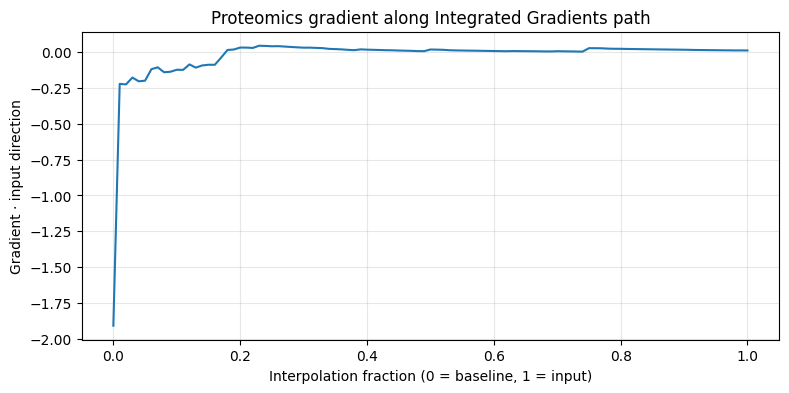


Gradient path diagnostic complete!


In [41]:

# WEEK 4 STEP 33: Inspect gradients along the IG path

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

full_model.eval()

# Examine one of the observations with larger IG error
observation_idx = 4

x = small_inputs[observation_idx:observation_idx + 1]
baseline = torch.zeros_like(x)

# Keep the matching non-proteomics inputs fixed
one_fixed_omics = {
    name: values[observation_idx:observation_idx + 1]
    for name, values in small_fixed_omics.items()
}

one_drug = small_drugs[observation_idx:observation_idx + 1]
one_sex = small_sexes[observation_idx:observation_idx + 1]

alphas = np.linspace(0, 1, 101)
gradient_dot_direction = []
path_predictions = []

direction = x - baseline

for alpha in alphas:

    interpolated = (
        baseline + float(alpha) * direction
    ).detach().requires_grad_(True)

    omics = {
        **one_fixed_omics,
        "proteomics": interpolated
    }

    prediction = full_model(
        omics, one_drug, one_sex
    )

    gradient = torch.autograd.grad(
        outputs=prediction.sum(),
        inputs=interpolated
    )[0]

    # Directional derivative along the baseline-to-input path
    directional_gradient = (
        gradient * direction
    ).sum().item()

    gradient_dot_direction.append(directional_gradient)
    path_predictions.append(prediction.item())

gradient_dot_direction = np.array(
    gradient_dot_direction
)

# Compare numerical integration to actual output difference
trapezoid_estimate = np.trapezoid(
    gradient_dot_direction,
    alphas
)

actual_difference = (
    path_predictions[-1] - path_predictions[0]
)

print("=== GRADIENT PATH DIAGNOSTIC ===")
print("Observation:", observation_idx)
print("Actual prediction change:", round(actual_difference, 6))
print("Gradient integral estimate:", round(trapezoid_estimate, 6))
print("Absolute difference:",
      round(abs(trapezoid_estimate - actual_difference), 6))

print("\nGradient range:")
print("Minimum:", round(gradient_dot_direction.min(), 6))
print("Maximum:", round(gradient_dot_direction.max(), 6))

# Visualize the gradients
plt.figure(figsize=(9, 4))
plt.plot(alphas, gradient_dot_direction)
plt.xlabel("Interpolation fraction (0 = baseline, 1 = input)")
plt.ylabel("Gradient · input direction")
plt.title("Proteomics gradient along Integrated Gradients path")
plt.grid(alpha=0.3)
plt.show()

print("\nGradient path diagnostic complete!")


In [42]:

# WEEK 4 STEP 34: Compare autograd with numerical slopes

import torch
import numpy as np
import pandas as pd

full_model.eval()

# Keep the same observation from Step 33
idx = 4

x = small_inputs[idx:idx + 1].detach()
direction = x.clone()

fixed = {
    name: values[idx:idx + 1]
    for name, values in small_fixed_omics.items()
}

drug = small_drugs[idx:idx + 1]
sex = small_sexes[idx:idx + 1]

def predict_at_alpha(alpha):
    protein_values = alpha * direction

    return full_model(
        {**fixed, "proteomics": protein_values},
        drug,
        sex
    )

# More points near the zero baseline
alphas = [
    0.0, 0.001, 0.005, 0.01, 0.02,
    0.05, 0.1, 0.2, 0.5, 0.9
]

epsilon = 0.0001
rows = []

for alpha in alphas:

    # Autograd directional derivative
    protein_values = (
        alpha * direction
    ).detach().requires_grad_(True)

    prediction = full_model(
        {**fixed, "proteomics": protein_values},
        drug,
        sex
    )

    gradient = torch.autograd.grad(
        prediction.sum(),
        protein_values
    )[0]

    autograd_slope = (
        gradient * direction
    ).sum().item()

    # Central finite-difference slope
    with torch.no_grad():
        plus = predict_at_alpha(alpha + epsilon)
        minus = predict_at_alpha(alpha - epsilon)

        numerical_slope = (
            (plus - minus) / (2 * epsilon)
        ).item()

    rows.append({
        "Alpha": alpha,
        "Autograd_slope": autograd_slope,
        "Numerical_slope": numerical_slope,
        "Absolute_difference": abs(
            autograd_slope - numerical_slope
        )
    })

gradient_check = pd.DataFrame(rows)

print("=== GRADIENT VALIDATION ===")
display(gradient_check.round(6))

print("\nMaximum slope disagreement:")
print(
    round(
        gradient_check["Absolute_difference"].max(),
        6
    )
)

print("\nGradient validation complete!")


=== GRADIENT VALIDATION ===


,Alpha,Autograd_slope,Numerical_slope,Absolute_difference
0,0.000,-1.907392,-1.749992,0.157400
1,0.001,-1.969680,-2.083778,0.114099
2,0.005,-0.208065,-0.208616,0.000551
3,0.010,-0.222366,-0.222921,0.000555
4,0.020,-0.226125,-0.225306,0.000820
5,0.050,-0.200183,-0.202656,0.002473
6,0.100,-0.124045,-0.123978,0.000067
7,0.200,0.030638,0.028610,0.002028
8,0.500,0.017083,0.016689,0.000394
9,0.900,0.015510,0.016689,0.001180



Maximum slope disagreement:
0.1574

Gradient validation complete!


In [43]:

# WEEK 4 STEP 35: Baseline-focused Integrated Gradients

import torch
import numpy as np
import pandas as pd

full_model.eval()

# Same 8 observations used in previous diagnostics
inputs = small_inputs.detach()
baseline = torch.zeros_like(inputs)

direction = inputs - baseline

def custom_integrated_gradients(alpha_grid):

    total_attribution = torch.zeros_like(inputs)

    for left, right in zip(alpha_grid[:-1], alpha_grid[1:]):

        midpoint = (left + right) / 2

        interpolated = (
            baseline + float(midpoint) * direction
        ).detach().requires_grad_(True)

        predictions = small_protein_forward(interpolated)

        gradients = torch.autograd.grad(
            outputs=predictions.sum(),
            inputs=interpolated
        )[0]

        total_attribution += (
            gradients.detach()
            * direction
            * float(right - left)
        )

    return total_attribution

# Standard uniform grid: 256 intervals
uniform_grid = np.linspace(0, 1, 257)

# Concentrate grid points near zero while covering 0 to 1
focused_grid = np.concatenate([
    np.linspace(0, 0.01, 129),
    np.linspace(0.01, 0.1, 65)[1:],
    np.linspace(0.1, 1.0, 65)[1:]
])

with torch.no_grad():
    prediction_change = (
        small_protein_forward(inputs)
        - small_protein_forward(baseline)
    )

results_custom = []

for name, grid in [
    ("Uniform_256", uniform_grid),
    ("Focused_256", focused_grid)
]:

    print(f"Calculating {name}...")

    attrs = custom_integrated_gradients(grid)

    error = (
        attrs.sum(dim=1) - prediction_change
    ).abs()

    relative_error = (
        error / prediction_change.abs().clamp(min=0.1)
    )

    results_custom.append({
        "Grid": name,
        "Intervals": len(grid) - 1,
        "Mean_abs_error": error.mean().item(),
        "Max_abs_error": error.max().item(),
        "Median_relative_error": relative_error.median().item(),
        "Below_10_percent": int(
            (relative_error < 0.10).sum().item()
        )
    })

grid_comparison = pd.DataFrame(results_custom)

print("\n=== INTEGRATION GRID COMPARISON ===")
display(grid_comparison.round(6))

grid_comparison.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_grid_comparison.csv",
    index=False
)

print("\nBaseline-focused integration test complete!")


Calculating Uniform_256...
Calculating Focused_256...

=== INTEGRATION GRID COMPARISON ===


,Grid,Intervals,Mean_abs_error,Max_abs_error,Median_relative_error,Below_10_percent
0,Uniform_256,256,0.049818,0.165111,0.228983,1
1,Focused_256,256,0.009824,0.017553,0.048124,4



Baseline-focused integration test complete!


In [44]:

# WEEK 4 STEP 36: Refine baseline-focused integration

import numpy as np
import pandas as pd

# Reuse custom_integrated_gradients from Step 35

focused_grids = {
    "Focused_256": [
        (0, 0.01, 128),
        (0.01, 0.1, 64),
        (0.1, 1.0, 64)
    ],
    "Focused_512": [
        (0, 0.01, 256),
        (0.01, 0.1, 128),
        (0.1, 1.0, 128)
    ],
    "Focused_1024": [
        (0, 0.01, 512),
        (0.01, 0.1, 256),
        (0.1, 1.0, 256)
    ]
}

refinement_results = []
refined_attrs = {}

for name, segments in focused_grids.items():

    parts = []

    for i, (start, end, intervals) in enumerate(segments):
        points = np.linspace(start, end, intervals + 1)

        if i > 0:
            points = points[1:]

        parts.append(points)

    grid = np.concatenate(parts)

    print(f"Calculating {name}...")

    attrs = custom_integrated_gradients(grid)
    refined_attrs[name] = attrs.detach().clone()

    error = (
        attrs.sum(dim=1) - prediction_change
    ).abs()

    relative_error = (
        error / prediction_change.abs().clamp(min=0.1)
    )

    refinement_results.append({
        "Grid": name,
        "Intervals": len(grid) - 1,
        "Mean_abs_error": error.mean().item(),
        "Max_abs_error": error.max().item(),
        "Median_relative_error": relative_error.median().item(),
        "Below_10_percent": int(
            (relative_error < 0.10).sum().item()
        )
    })

refinement_summary = pd.DataFrame(refinement_results)

print("\n=== REFINED INTEGRATION RESULTS ===")
display(refinement_summary.round(6))

# Compare attribution stability at 512 vs 1024 intervals
difference = (
    refined_attrs["Focused_1024"]
    - refined_attrs["Focused_512"]
).abs()

relative_change = (
    difference.sum(dim=1)
    / refined_attrs["Focused_1024"].abs()
      .sum(dim=1)
      .clamp(min=1e-8)
)

print("\n=== ATTRIBUTION STABILITY ===")
print(
    "Median relative attribution change, 512 vs 1024:",
    round(relative_change.median().item(), 4)
)

refinement_summary.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_refined_grid.csv",
    index=False
)

print("\nGrid refinement complete!")


Calculating Focused_256...
Calculating Focused_512...
Calculating Focused_1024...

=== REFINED INTEGRATION RESULTS ===


,Grid,Intervals,Mean_abs_error,Max_abs_error,Median_relative_error,Below_10_percent
0,Focused_256,256,0.009824,0.017553,0.048124,4
1,Focused_512,512,0.012168,0.019389,0.108773,3
2,Focused_1024,1024,0.009119,0.018653,0.061262,4



=== ATTRIBUTION STABILITY ===
Median relative attribution change, 512 vs 1024: 0.0249

Grid refinement complete!


In [45]:

# WEEK 4 STEP 37: Locate IG integration errors

import numpy as np
import pandas as pd
import torch

full_model.eval()

regions = [
    (0.0, 0.01, 512, "Near baseline"),
    (0.01, 0.1, 256, "Early path"),
    (0.1, 1.0, 256, "Remaining path")
]

region_results = []

# Reuse the same eight observations
inputs = small_inputs.detach()
direction = inputs.clone()

for start, end, n_intervals, label in regions:

    print(f"Checking {label}: {start} to {end}")

    grid = np.linspace(start, end, n_intervals + 1)

    # Calculate integrated gradients for this region
    attrs = custom_integrated_gradients(grid)

    # Evaluate predictions at both region boundaries
    with torch.no_grad():
        prediction_start = small_protein_forward(
            start * direction
        )

        prediction_end = small_protein_forward(
            end * direction
        )

    actual_change = prediction_end - prediction_start
    estimated_change = attrs.sum(dim=1)

    errors = (
        estimated_change - actual_change
    ).abs()

    region_results.append({
        "Region": label,
        "Alpha_start": start,
        "Alpha_end": end,
        "Intervals": n_intervals,
        "Mean_abs_error": errors.mean().item(),
        "Max_abs_error": errors.max().item(),
        "Worst_observation": errors.argmax().item()
    })

region_diagnostic = pd.DataFrame(region_results)

print("\n=== ERROR BY INTEGRATION REGION ===")
display(region_diagnostic.round(6))

region_diagnostic.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_error_by_region.csv",
    index=False
)

print("\nRegional diagnostic complete!")


Checking Near baseline: 0.0 to 0.01
Checking Early path: 0.01 to 0.1
Checking Remaining path: 0.1 to 1.0

=== ERROR BY INTEGRATION REGION ===


,Region,Alpha_start,Alpha_end,Intervals,Mean_abs_error,Max_abs_error,Worst_observation
0,Near baseline,0.00,0.01,512,0.000210,0.000449,4
1,Early path,0.01,0.10,256,0.000011,0.000023,0
2,Remaining path,0.10,1.00,256,0.009293,0.019105,4



Regional diagnostic complete!


In [46]:

# WEEK 4 STEP 38: Refine the problematic integration region

import numpy as np
import pandas as pd
import torch

full_model.eval()

# Reuse the eight observations from earlier steps
inputs = small_inputs.detach()
direction = inputs.clone()

# Keep the two well-resolved regions fixed
near_baseline_grid = np.linspace(0, 0.01, 513)
early_grid = np.linspace(0.01, 0.1, 257)

# Calculate these attributions once
near_attrs = custom_integrated_gradients(
    near_baseline_grid
)

early_attrs = custom_integrated_gradients(
    early_grid
)

with torch.no_grad():
    actual_change = (
        small_protein_forward(inputs)
        - small_protein_forward(torch.zeros_like(inputs))
    )

refinement_rows = []

for remaining_steps in [256, 512, 1024]:

    print(
        f"Testing remaining region with "
        f"{remaining_steps} intervals..."
    )

    remaining_grid = np.linspace(
        0.1, 1.0, remaining_steps + 1
    )

    remaining_attrs = custom_integrated_gradients(
        remaining_grid
    )

    # Combine the attributions across all three regions
    total_attrs = (
        near_attrs + early_attrs + remaining_attrs
    )

    error = (
        total_attrs.sum(dim=1) - actual_change
    ).abs()

    relative_error = (
        error / actual_change.abs().clamp(min=0.1)
    )

    refinement_rows.append({
        "Remaining_intervals": remaining_steps,
        "Total_intervals": 512 + 256 + remaining_steps,
        "Mean_abs_error": error.mean().item(),
        "Max_abs_error": error.max().item(),
        "Median_relative_error": relative_error.median().item(),
        "Below_10_percent": int(
            (relative_error < 0.10).sum().item()
        )
    })

regional_refinement = pd.DataFrame(refinement_rows)

print("\n=== TARGETED INTEGRATION REFINEMENT ===")
display(regional_refinement.round(6))

regional_refinement.to_csv(
    "/content/week4_ablation_results/"
    "protein_IG_targeted_refinement.csv",
    index=False
)

print("\nTargeted integration refinement complete!")


Testing remaining region with 256 intervals...
Testing remaining region with 512 intervals...
Testing remaining region with 1024 intervals...

=== TARGETED INTEGRATION REFINEMENT ===


,Remaining_intervals,Total_intervals,Mean_abs_error,Max_abs_error,Median_relative_error,Below_10_percent
0,256,1024,0.009119,0.018653,0.061262,4
1,512,1280,0.009186,0.018338,0.067105,4
2,1024,1792,0.029065,0.055666,0.190689,2



Targeted integration refinement complete!


In [47]:

# WEEK 4 STEP 39: Adaptive gradient integration

import torch
import numpy as np
from scipy.integrate import quad

full_model.eval()

# Observation with large previous completeness error
idx = 4

x = small_inputs[idx:idx + 1].detach()
direction = x.clone()

fixed = {
    name: values[idx:idx + 1]
    for name, values in small_fixed_omics.items()
}

drug = small_drugs[idx:idx + 1]
sex = small_sexes[idx:idx + 1]

# Directional gradient along the attribution path
def directional_gradient(alpha):

    interpolated = (
        float(alpha) * direction
    ).detach().requires_grad_(True)

    omics = {
        **fixed,
        "proteomics": interpolated
    }

    prediction = full_model(
        omics,
        drug,
        sex
    )

    gradient = torch.autograd.grad(
        prediction.sum(),
        interpolated
    )[0]

    return float(
        (gradient * direction).sum().item()
    )

# Adaptive quadrature, with explicit region boundaries
integral, estimated_error = quad(
    directional_gradient,
    0.0,
    1.0,
    points=[0.001, 0.01, 0.1],
    epsabs=1e-4,
    epsrel=1e-4,
    limit=200
)

# Compare against the actual prediction difference
with torch.no_grad():

    input_prediction = full_model(
        {**fixed, "proteomics": x},
        drug,
        sex
    ).item()

    baseline_prediction = full_model(
        {
            **fixed,
            "proteomics": torch.zeros_like(x)
        },
        drug,
        sex
    ).item()

actual_change = input_prediction - baseline_prediction

print("=== ADAPTIVE INTEGRATION RESULTS ===")

print("Actual prediction change:",
      round(actual_change, 6))

print("Adaptive gradient integral:",
      round(integral, 6))

print("Absolute completeness error:",
      round(abs(integral - actual_change), 6))

print("Estimated integration error:",
      round(estimated_error, 6))

print("\nAdaptive integration diagnostic complete!")


=== ADAPTIVE INTEGRATION RESULTS ===
Actual prediction change: -0.064804
Adaptive gradient integral: -0.046031
Absolute completeness error: 0.018772
Estimated integration error: 0.000807

Adaptive integration diagnostic complete!


/tmp/ipykernel_1080/364625652.py:51: IntegrationWarning: The maximum number of subdivisions (200) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, estimated_error = quad(


=== PREDICTION CONTINUITY CHECK ===
All predictions finite: True
Maximum adjacent change: 0.016030550003051758
Median adjacent change: 8.58306884765625e-06

=== LARGEST LOCAL PREDICTION CHANGES ===


,Alpha_start,Alpha_end,Prediction_start,Prediction_end,Absolute_change
0,0.3315,0.3320,3.835367,3.819336,0.016031
1,0.0015,0.0020,3.878341,3.865395,0.012946
2,0.0000,0.0005,3.892578,3.882840,0.009737
3,0.0010,0.0015,3.882377,3.878341,0.004036
4,0.0020,0.0025,3.865395,3.862384,0.003010
5,0.3310,0.3315,3.838340,3.835367,0.002973
6,0.0065,0.0070,3.861102,3.858638,0.002464
7,0.0070,0.0075,3.858638,3.857324,0.001314
8,0.0075,0.0080,3.857324,3.856424,0.000900
9,0.0005,0.0010,3.882840,3.882377,0.000463


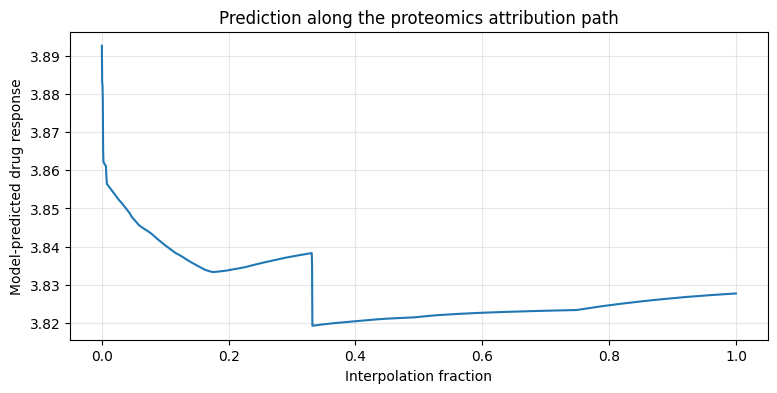


Prediction continuity diagnostic complete!


In [48]:

# WEEK 4 STEP 40: Check prediction continuity

import torch
import numpy as np
import pandas as pd

full_model.eval()

# Same observation as Step 39
idx = 4

x = small_inputs[idx:idx + 1].detach()

fixed = {
    name: values[idx:idx + 1]
    for name, values in small_fixed_omics.items()
}

drug = small_drugs[idx:idx + 1]
sex = small_sexes[idx:idx + 1]

def prediction_at(alpha):
    with torch.no_grad():
        return full_model(
            {
                **fixed,
                "proteomics": float(alpha) * x
            },
            drug,
            sex
        ).item()

# Sample the entire interpolation path
alphas = np.linspace(0, 1, 2001)

predictions = np.array([
    prediction_at(alpha)
    for alpha in alphas
])

# Find the largest changes between adjacent points
differences = np.abs(np.diff(predictions))

largest_indices = np.argsort(differences)[-10:][::-1]

rows = []

for i in largest_indices:
    rows.append({
        "Alpha_start": alphas[i],
        "Alpha_end": alphas[i + 1],
        "Prediction_start": predictions[i],
        "Prediction_end": predictions[i + 1],
        "Absolute_change": differences[i]
    })

continuity_results = pd.DataFrame(rows)

print("=== PREDICTION CONTINUITY CHECK ===")

print("All predictions finite:", np.isfinite(predictions).all())
print("Maximum adjacent change:", differences.max())
print("Median adjacent change:", np.median(differences))

print("\n=== LARGEST LOCAL PREDICTION CHANGES ===")
display(continuity_results.round(6))

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(alphas, predictions)
plt.xlabel("Interpolation fraction")
plt.ylabel("Model-predicted drug response")
plt.title("Prediction along the proteomics attribution path")
plt.grid(alpha=0.3)
plt.show()

print("\nPrediction continuity diagnostic complete!")


In [49]:

# WEEK 4 STEP 41: Protein attribution screening
# Gradient x Input, without numerical integration

import torch
import numpy as np
import pandas as pd
from pathlib import Path

full_model.eval()

experiment = ablation_data["cell_blind"]
test_pairs = experiment["pairs"].query(
    "split == 'test'"
).reset_index(drop=True)

# Sample 64 observations from each sex group
rng = np.random.default_rng(42)

selected_indices = []

for sex_idx in [0, 1]:
    candidates = np.where(
        test_pairs["sex_idx"].to_numpy() == sex_idx
    )[0]

    selected_indices.extend(
        rng.choice(candidates, size=64, replace=False)
    )

selected_indices = np.array(selected_indices)

sample = test_pairs.iloc[selected_indices]

cells = torch.tensor(
    sample["cell_idx"].to_numpy(),
    dtype=torch.long,
    device=device
)

drugs = torch.tensor(
    sample["drug_idx"].to_numpy(),
    dtype=torch.long,
    device=device
)

sexes = torch.tensor(
    sample["sex_idx"].to_numpy(),
    dtype=torch.long,
    device=device
)

# Fixed non-proteomics inputs
omics = {
    name: experiment["tensors"][name][cells]
    for name in ["expression", "mutation", "cnv"]
}

# Protein values require gradients
protein_values = (
    experiment["tensors"]["proteomics"][cells]
    .detach()
    .clone()
    .requires_grad_(True)
)

omics["proteomics"] = protein_values

# Calculate predictions
predictions = full_model(
    omics, drugs, sexes
)

# Gradient of predicted response with respect to proteins
protein_gradients = torch.autograd.grad(
    outputs=predictions.sum(),
    inputs=protein_values
)[0]

# Gradient x Input attribution
attributions = (
    protein_gradients * protein_values
).detach().cpu().numpy()

# Rank by mean absolute attribution
protein_names = (
    ablation_omics["cell_blind"]["proteomics"]
    .columns.tolist()
)

ranking = pd.DataFrame({
    "Protein": protein_names,
    "Mean_absolute_gradient_x_input":
        np.abs(attributions).mean(axis=0)
})

ranking = ranking.sort_values(
    "Mean_absolute_gradient_x_input",
    ascending=False
).reset_index(drop=True)

output_dir = Path("/content/week4_ablation_results")

ranking.to_csv(
    output_dir / "protein_gradient_screening.csv",
    index=False
)

print("=== PROTEIN ATTRIBUTION SCREENING ===")
print("Observations analyzed:", len(sample))
print("Protein features:", len(protein_names))
print("All attributions finite:",
      np.isfinite(attributions).all())

print("\n=== TOP 20 PROTEINS ===")
display(ranking.head(20))

print("\nGradient-based screening complete!")


=== PROTEIN ATTRIBUTION SCREENING ===
Observations analyzed: 128
Protein features: 4153
All attributions finite: True

=== TOP 20 PROTEINS ===


,Protein,Mean_absolute_gradient_x_input
0,P28702;RXRB_HUMAN,0.003866
1,P07996;TSP1_HUMAN,0.003487
2,P48960;AGRE5_HUMAN,0.003091
3,P61513;RL37A_HUMAN,0.002725
4,P46019;KPB2_HUMAN,0.002523
5,Q9NPF0;CD320_HUMAN,0.002506
6,Q8TEM1;PO210_HUMAN,0.002418
7,Q9P0T7;TMEM9_HUMAN,0.002416
8,Q7Z2Z2;EFL1_HUMAN,0.002378
9,Q96IU4;ABHEB_HUMAN,0.002314



Gradient-based screening complete!


In [50]:

# WEEK 4 STEP 42: Validate top proteins by feature ablation

import torch
import numpy as np
import pandas as pd
from pathlib import Path

full_model.eval()

# Reuse the same 128 observations from Step 41
base_proteins = protein_values.detach().clone()

fixed_omics = {
    name: experiment["tensors"][name][cells]
    for name in ["expression", "mutation", "cnv"]
}

# Original predictions
with torch.no_grad():
    original_predictions = full_model(
        {
            **fixed_omics,
            "proteomics": base_proteins
        },
        drugs,
        sexes
    )

# Select the top 20 screened proteins
top_proteins = ranking.head(20)["Protein"].tolist()

protein_to_idx = {
    name: i
    for i, name in enumerate(protein_names)
}

validation_rows = []

for protein in top_proteins:

    idx = protein_to_idx[protein]

    # Remove this protein's deviation from the zero reference
    modified_proteins = base_proteins.clone()
    modified_proteins[:, idx] = 0.0

    with torch.no_grad():
        modified_predictions = full_model(
            {
                **fixed_omics,
                "proteomics": modified_proteins
            },
            drugs,
            sexes
        )

    # Prediction change caused by removing this feature
    changes = (
        modified_predictions - original_predictions
    ).cpu().numpy()

    sex_labels = sexes.cpu().numpy()

    validation_rows.append({
        "Protein": protein,
        "Mean_absolute_prediction_change":
            np.abs(changes).mean(),
        "Female_mean_absolute_change":
            np.abs(changes[sex_labels == 0]).mean(),
        "Male_mean_absolute_change":
            np.abs(changes[sex_labels == 1]).mean(),
        "Mean_signed_change":
            changes.mean()
    })

validation = pd.DataFrame(validation_rows)

validation = validation.sort_values(
    "Mean_absolute_prediction_change",
    ascending=False
).reset_index(drop=True)

# Add original gradient-screening scores
validation = validation.merge(
    ranking[
        ["Protein", "Mean_absolute_gradient_x_input"]
    ],
    on="Protein",
    how="left"
)

# Save the results
output_dir = Path("/content/week4_ablation_results")

validation.to_csv(
    output_dir / "protein_feature_ablation_validation.csv",
    index=False
)

print("=== FEATURE ABLATION VALIDATION ===")
print("Proteins tested:", len(validation))
print("Observations:", len(base_proteins))

print("\n=== TOP 20 VALIDATED PROTEINS ===")
display(validation.round(6))

# Compare gradient and perturbation rankings
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    validation["Mean_absolute_gradient_x_input"],
    validation["Mean_absolute_prediction_change"]
)

print("\n=== RANKING AGREEMENT ===")
print("Spearman correlation:", round(correlation, 4))
print("Descriptive p-value:", round(p_value, 4))

print("\nFeature ablation validation complete!")


=== FEATURE ABLATION VALIDATION ===
Proteins tested: 20
Observations: 128

=== TOP 20 VALIDATED PROTEINS ===


,Protein,Mean_absolute_prediction_change,Female_mean_absolute_change,Male_mean_absolute_change,Mean_signed_change,Mean_absolute_gradient_x_input
0,Q8WY22;BRI3B_HUMAN,0.002293,0.004167,0.000420,-0.001541,0.001969
1,P07996;TSP1_HUMAN,0.002215,0.004001,0.000429,-0.002036,0.003487
2,Q9P0T7;TMEM9_HUMAN,0.002186,0.004092,0.000280,-0.001901,0.002416
3,P28702;RXRB_HUMAN,0.002182,0.003973,0.000392,-0.001653,0.003866
4,Q8TEM1;PO210_HUMAN,0.002104,0.003845,0.000363,-0.001614,0.002418
5,Q9H4I3;TRABD_HUMAN,0.002049,0.003755,0.000342,-0.001660,0.002196
6,P61513;RL37A_HUMAN,0.002043,0.003813,0.000272,-0.001483,0.002725
7,Q8WTV0;SCRB1_HUMAN,0.001908,0.003668,0.000149,-0.001793,0.002001
8,Q7Z2Z2;EFL1_HUMAN,0.001868,0.003602,0.000134,-0.001675,0.002378
9,Q9UHL4;DPP2_HUMAN,0.000936,0.000498,0.001375,0.000221,0.002018



=== RANKING AGREEMENT ===
Spearman correlation: 0.2842
Descriptive p-value: 0.2246

Feature ablation validation complete!


In [52]:

# WEEK 4 STEP 43 FIX: Audit attribution sample

import pandas as pd

# Restore the same 128 observations from Step 41
audit = sample.copy()

# Only add tissue metadata if it isn't already present
if "Tissue_type" not in audit.columns:
    tissue_lookup = (
        sex_metadata[["SIDM", "Tissue_type"]]
        .drop_duplicates("SIDM")
    )

    audit = audit.merge(
        tissue_lookup,
        on="SIDM",
        how="left",
        validate="many_to_one"
    )

print("=== SAMPLE COMPOSITION ===")

for sex_label in ["Female", "Male"]:

    group = audit[
        audit["final_sex"] == sex_label
    ]

    print(f"\n=== {sex_label.upper()} ===")
    print("Drug-response observations:", len(group))
    print("Unique cell lines:", group["SIDM"].nunique())
    print("Unique drugs:", group["Drug_ID"].nunique())
    print("Unique tissues:", group["Tissue_type"].nunique())

    print("\nMost represented cell lines:")
    print(group["SIDM"].value_counts().head(5))

    print("\nMost represented tissues:")
    print(group["Tissue_type"].value_counts().head(8))

# Tissue overlap between sex groups
female_tissues = set(
    audit.loc[
        audit["final_sex"] == "Female",
        "Tissue_type"
    ].dropna()
)

male_tissues = set(
    audit.loc[
        audit["final_sex"] == "Male",
        "Tissue_type"
    ].dropna()
)

print("\n=== TISSUE OVERLAP ===")
print("Shared tissues:", len(female_tissues & male_tissues))
print("Female-only tissues:", len(female_tissues - male_tissues))
print("Male-only tissues:", len(male_tissues - female_tissues))

print("\n=== CELL-LINE SAMPLING ===")
print("Total unique cell lines:", audit["SIDM"].nunique())
print(
    "Maximum observations from one cell line:",
    audit["SIDM"].value_counts().max()
)

print("\nSample audit complete!")


=== SAMPLE COMPOSITION ===

=== FEMALE ===
Drug-response observations: 64
Unique cell lines: 26
Unique drugs: 54
Unique tissues: 12

Most represented cell lines:
SIDM
SIDM00735    5
SIDM00936    5
SIDM00428    4
SIDM00284    4
SIDM01090    4
Name: count, dtype: int64

Most represented tissues:
Tissue_type
Lung                           14
Breast                          8
Large Intestine                 7
Haematopoietic and Lymphoid     6
Soft Tissue                     6
Bladder                         5
Ovary                           5
Skin                            4
Name: count, dtype: int64

=== MALE ===
Drug-response observations: 64
Unique cell lines: 33
Unique drugs: 57
Unique tissues: 13

Most represented cell lines:
SIDM
SIDM00344    4
SIDM00418    4
SIDM01010    3
SIDM00778    3
SIDM00081    3
Name: count, dtype: int64

Most represented tissues:
Tissue_type
Lung                           20
Skin                            9
Haematopoietic and Lymphoid     7
Central Nervous

In [53]:

# WEEK 4 STEP 44: Identify tissues suitable for sex comparison

import pandas as pd

# Use all official cell-line-blind test observations
test_pairs = (
    ablation_data["cell_blind"]["pairs"]
    .query("split == 'test'")
    .copy()
)

# One record per biological cell line
cell_line_table = (
    test_pairs[
        ["SIDM", "final_sex", "Tissue_type"]
    ]
    .drop_duplicates()
)

# Count unique cell lines by sex and tissue
tissue_counts = (
    cell_line_table
    .groupby(["Tissue_type", "final_sex"])["SIDM"]
    .nunique()
    .unstack(fill_value=0)
)

# Make sure both columns exist
for sex in ["Female", "Male"]:
    if sex not in tissue_counts.columns:
        tissue_counts[sex] = 0

tissue_counts = tissue_counts[
    ["Female", "Male"]
]

tissue_counts["Matched_pairs_possible"] = (
    tissue_counts[["Female", "Male"]].min(axis=1)
)

tissue_counts["Total_cell_lines"] = (
    tissue_counts["Female"] + tissue_counts["Male"]
)

tissue_counts = tissue_counts.sort_values(
    ["Matched_pairs_possible", "Total_cell_lines"],
    ascending=False
)

print("=== CELL-LINE SEX DISTRIBUTION BY TISSUE ===")
display(tissue_counts)

print("\n=== MATCHING CAPACITY ===")
print(
    "Tissues containing both sexes:",
    int((tissue_counts["Matched_pairs_possible"] > 0).sum())
)

print(
    "Maximum possible female-male cell-line pairs:",
    int(tissue_counts["Matched_pairs_possible"].sum())
)

print(
    "Tissues with at least 2 cell lines per sex:",
    int((tissue_counts["Matched_pairs_possible"] >= 2).sum())
)

# Save for subsequent sampling
tissue_counts.to_csv(
    "/content/week4_ablation_results/"
    "attribution_tissue_matching_capacity.csv"
)

print("\nTissue matching audit complete!")


=== CELL-LINE SEX DISTRIBUTION BY TISSUE ===


final_sex,Female,Male,Matched_pairs_possible,Total_cell_lines
Tissue_type,,,,
Lung,8,13,8,21
Haematopoietic and Lymphoid,4,4,4,8
Large Intestine,2,3,2,5
Skin,1,4,1,5
Bladder,1,2,1,3
Esophagus,1,2,1,3
Bone,1,1,1,2
Peripheral Nervous System,1,1,1,2
Thyroid,1,1,1,2



=== MATCHING CAPACITY ===
Tissues containing both sexes: 9
Maximum possible female-male cell-line pairs: 20
Tissues with at least 2 cell lines per sex: 3

Tissue matching audit complete!


In [54]:

# WEEK 4 STEP 45: Check shared drugs within tissues

import pandas as pd

test_pairs = (
    ablation_data["cell_blind"]["pairs"]
    .query("split == 'test'")
    .copy()
)

overlap_rows = []

for tissue, group in test_pairs.groupby("Tissue_type"):

    female = group[group["final_sex"] == "Female"]
    male = group[group["final_sex"] == "Male"]

    female_drugs = set(female["Drug_ID"])
    male_drugs = set(male["Drug_ID"])

    shared_drugs = female_drugs & male_drugs

    # Count shared-drug observations in each group
    female_shared = female[
        female["Drug_ID"].isin(shared_drugs)
    ]

    male_shared = male[
        male["Drug_ID"].isin(shared_drugs)
    ]

    overlap_rows.append({
        "Tissue": tissue,
        "Female_cells": female["SIDM"].nunique(),
        "Male_cells": male["SIDM"].nunique(),
        "Shared_drugs": len(shared_drugs),
        "Female_shared_observations": len(female_shared),
        "Male_shared_observations": len(male_shared)
    })

drug_overlap = pd.DataFrame(overlap_rows)

# Retain tissues with both sexes
drug_overlap = drug_overlap[
    (drug_overlap["Female_cells"] > 0)
    & (drug_overlap["Male_cells"] > 0)
].sort_values(
    ["Shared_drugs", "Female_cells"],
    ascending=False
).reset_index(drop=True)

print("=== TISSUE AND DRUG OVERLAP ===")
display(drug_overlap)

print("\n=== TOTAL MATCHING CAPACITY ===")
print(
    "Tissues with shared drugs:",
    int((drug_overlap["Shared_drugs"] > 0).sum())
)

print(
    "Total shared tissue-drug combinations:",
    int(drug_overlap["Shared_drugs"].sum())
)

print(
    "Female observations involving shared drugs:",
    int(drug_overlap["Female_shared_observations"].sum())
)

print(
    "Male observations involving shared drugs:",
    int(drug_overlap["Male_shared_observations"].sum())
)

drug_overlap.to_csv(
    "/content/week4_ablation_results/"
    "attribution_tissue_drug_overlap.csv",
    index=False
)

print("\nTissue-drug overlap analysis complete!")


=== TISSUE AND DRUG OVERLAP ===


,Tissue,Female_cells,Male_cells,Shared_drugs,Female_shared_observations,Male_shared_observations
0,Lung,8,13,266,1528,3005
1,Haematopoietic and Lymphoid,4,4,266,873,908
2,Large Intestine,2,3,266,527,739
3,Bladder,1,2,216,216,383
4,Esophagus,1,2,216,216,425
5,Skin,1,4,216,216,774
6,Thyroid,1,1,213,213,213
7,Peripheral Nervous System,1,1,204,204,204
8,Bone,1,1,193,193,193



=== TOTAL MATCHING CAPACITY ===
Tissues with shared drugs: 9
Total shared tissue-drug combinations: 2056
Female observations involving shared drugs: 4186
Male observations involving shared drugs: 6844

Tissue-drug overlap analysis complete!


In [55]:

# WEEK 4 STEP 46: Build matched attribution sample

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

test_pairs = (
    ablation_data["cell_blind"]["pairs"]
    .query("split == 'test'")
    .copy()
)

selected_tissues = [
    "Lung",
    "Haematopoietic and Lymphoid",
    "Large Intestine"
]

matched_rows = []
pair_id = 0

for tissue in selected_tissues:

    tissue_data = test_pairs[
        test_pairs["Tissue_type"] == tissue
    ]

    female_ids = (
        tissue_data.loc[
            tissue_data["final_sex"] == "Female",
            "SIDM"
        ]
        .drop_duplicates()
        .to_numpy()
    )

    male_ids = (
        tissue_data.loc[
            tissue_data["final_sex"] == "Male",
            "SIDM"
        ]
        .drop_duplicates()
        .to_numpy()
    )

    # Shuffle before pairing, to avoid ordering bias
    rng.shuffle(female_ids)
    rng.shuffle(male_ids)

    n_pairs = min(len(female_ids), len(male_ids))

    for female_id, male_id in zip(
        female_ids[:n_pairs],
        male_ids[:n_pairs]
    ):

        female = tissue_data[
            tissue_data["SIDM"] == female_id
        ]

        male = tissue_data[
            tissue_data["SIDM"] == male_id
        ]

        # Drugs measured in both cell lines
        common_drugs = (
            set(female["Drug_ID"])
            & set(male["Drug_ID"])
        )

        if not common_drugs:
            continue

        # Limit each pair to 10 shared drugs
        selected_drugs = rng.choice(
            sorted(common_drugs),
            size=min(10, len(common_drugs)),
            replace=False
        )

        for drug_id in selected_drugs:

            female_row = female[
                female["Drug_ID"] == drug_id
            ]

            male_row = male[
                male["Drug_ID"] == drug_id
            ]

            assert len(female_row) == 1
            assert len(male_row) == 1

            for row in [female_row, male_row]:

                record = row.iloc[0].to_dict()
                record["Pair_ID"] = pair_id
                matched_rows.append(record)

        pair_id += 1

matched_sample = pd.DataFrame(matched_rows)

print("=== MATCHED ATTRIBUTION SAMPLE ===")
print("Total observations:", len(matched_sample))
print("Unique cell lines:", matched_sample["SIDM"].nunique())
print("Unique drugs:", matched_sample["Drug_ID"].nunique())
print("Cell-line pairs:", matched_sample["Pair_ID"].nunique())

print("\n=== OBSERVATIONS BY TISSUE AND SEX ===")
display(
    matched_sample.groupby(
        ["Tissue_type", "final_sex"]
    ).size().unstack(fill_value=0)
)

print("\n=== MATCHING VERIFICATION ===")

pair_check = matched_sample.groupby(
    ["Pair_ID", "Drug_ID"]
)["final_sex"].nunique()

assert (pair_check == 2).all()

print("Every selected drug has a female and male observation.")

# Save the sample for reproducibility
matched_sample.to_csv(
    "/content/week4_ablation_results/"
    "matched_attribution_sample.csv",
    index=False
)

print("\nMatched attribution sample ready!")


=== MATCHED ATTRIBUTION SAMPLE ===
Total observations: 280
Unique cell lines: 28
Unique drugs: 101
Cell-line pairs: 14

=== OBSERVATIONS BY TISSUE AND SEX ===


final_sex,Female,Male
Tissue_type,,
Haematopoietic and Lymphoid,40,40
Large Intestine,20,20
Lung,80,80



=== MATCHING VERIFICATION ===
Every selected drug has a female and male observation.

Matched attribution sample ready!


In [56]:

# WEEK 4 STEP 47: Tissue- and drug-matched protein analysis

import torch
import numpy as np
import pandas as pd
from pathlib import Path

full_model.eval()

experiment = ablation_data["cell_blind"]
matched = matched_sample.reset_index(drop=True).copy()

# Rebuild PyTorch indices for matched observations
matched_cells = torch.tensor(
    matched["cell_idx"].to_numpy(),
    dtype=torch.long, device=device
)

matched_drugs = torch.tensor(
    matched["drug_idx"].to_numpy(),
    dtype=torch.long, device=device
)

matched_sexes = torch.tensor(
    matched["sex_idx"].to_numpy(),
    dtype=torch.long, device=device
)

# Retrieve all four omics modalities
matched_omics = {
    name: matrix[matched_cells]
    for name, matrix in experiment["tensors"].items()
}

# Original full-model predictions
with torch.no_grad():
    baseline_predictions = full_model(
        matched_omics,
        matched_drugs,
        matched_sexes
    )

# Reuse the 20 proteins selected in Step 41
top_proteins = ranking.head(20)["Protein"].tolist()

protein_to_idx = {
    name: i for i, name in enumerate(protein_names)
}

results_matched = []

for protein in top_proteins:

    feature_idx = protein_to_idx[protein]

    # Replace one standardized protein feature with zero
    modified = matched_omics["proteomics"].clone()
    modified[:, feature_idx] = 0.0

    modified_omics = {
        **matched_omics,
        "proteomics": modified
    }

    with torch.no_grad():
        new_predictions = full_model(
            modified_omics,
            matched_drugs,
            matched_sexes
        )

    changes = (
        new_predictions - baseline_predictions
    ).abs().cpu().numpy()

    temp = matched[
        ["Pair_ID", "Drug_ID", "Tissue_type", "final_sex"]
    ].copy()

    temp["Absolute_change"] = changes

    # One female and one male observation for each pair/drug
    paired = temp.pivot(
        index=["Pair_ID", "Drug_ID", "Tissue_type"],
        columns="final_sex",
        values="Absolute_change"
    ).reset_index()

    paired["Female_minus_Male"] = (
        paired["Female"] - paired["Male"]
    )

    # Average within each matched cell-line pair
    pair_means = paired.groupby(
        ["Pair_ID", "Tissue_type"]
    )[["Female", "Male", "Female_minus_Male"]].mean()

    results_matched.append({
        "Protein": protein,
        "Female_mean_change": pair_means["Female"].mean(),
        "Male_mean_change": pair_means["Male"].mean(),
        "Female_minus_Male": pair_means[
            "Female_minus_Male"
        ].mean(),
        "Pairs_Female_higher": int(
            (pair_means["Female_minus_Male"] > 0).sum()
        ),
        "Pairs_Male_higher": int(
            (pair_means["Female_minus_Male"] < 0).sum()
        )
    })

matched_validation = pd.DataFrame(results_matched)

# Rank by average model response to perturbation
matched_validation["Overall_mean_change"] = (
    matched_validation["Female_mean_change"]
    + matched_validation["Male_mean_change"]
) / 2

matched_validation = matched_validation.sort_values(
    "Overall_mean_change",
    ascending=False
).reset_index(drop=True)

output_dir = Path("/content/week4_ablation_results")

matched_validation.to_csv(
    output_dir / "matched_protein_attribution_results.csv",
    index=False
)

print("=== MATCHED PROTEIN ATTRIBUTION RESULTS ===")
print("Matched cell-line pairs:", matched["Pair_ID"].nunique())
print("Proteins tested:", len(matched_validation))

display(matched_validation.round(6))

print("\n=== TOP 5 PROTEINS BY MATCHED PERTURBATION EFFECT ===")
display(matched_validation.head(5).round(6))

print("\nMatched protein analysis complete!")


=== MATCHED PROTEIN ATTRIBUTION RESULTS ===
Matched cell-line pairs: 14
Proteins tested: 20


,Protein,Female_mean_change,Male_mean_change,Female_minus_Male,Pairs_Female_higher,Pairs_Male_higher,Overall_mean_change
0,Q8WY22;BRI3B_HUMAN,0.000929,0.000643,0.000286,7,7,0.000786
1,P48960;AGRE5_HUMAN,0.000967,0.000603,0.000364,8,6,0.000785
2,P07996;TSP1_HUMAN,0.000733,0.000499,0.000234,8,6,0.000616
3,Q99543;DNJC2_HUMAN,0.000755,0.000460,0.000295,9,5,0.000608
4,P28702;RXRB_HUMAN,0.000591,0.000378,0.000213,8,6,0.000485
5,Q9Y320;TMX2_HUMAN,0.000507,0.000430,0.000077,9,5,0.000469
6,P08195;4F2_HUMAN,0.000362,0.000448,-0.000086,6,8,0.000405
7,Q9UHL4;DPP2_HUMAN,0.000390,0.000377,0.000013,9,5,0.000384
8,Q01650;LAT1_HUMAN,0.000312,0.000415,-0.000104,6,8,0.000363
9,Q9P0T7;TMEM9_HUMAN,0.000467,0.000245,0.000222,11,3,0.000356



=== TOP 5 PROTEINS BY MATCHED PERTURBATION EFFECT ===


,Protein,Female_mean_change,Male_mean_change,Female_minus_Male,Pairs_Female_higher,Pairs_Male_higher,Overall_mean_change
0,Q8WY22;BRI3B_HUMAN,0.000929,0.000643,0.000286,7,7,0.000786
1,P48960;AGRE5_HUMAN,0.000967,0.000603,0.000364,8,6,0.000785
2,P07996;TSP1_HUMAN,0.000733,0.000499,0.000234,8,6,0.000616
3,Q99543;DNJC2_HUMAN,0.000755,0.000460,0.000295,9,5,0.000608
4,P28702;RXRB_HUMAN,0.000591,0.000378,0.000213,8,6,0.000485



Matched protein analysis complete!


In [57]:

# WEEK 4 STEP 48: Prepare protein IDs for pathway analysis

import pandas as pd
from pathlib import Path

output_dir = Path("/content/week4_ablation_results")

# Complete measured-protein background
protein_background = pd.DataFrame({
    "Original_ID": protein_names
})

# Split UniProt accession from protein entry name
protein_background["UniProt"] = (
    protein_background["Original_ID"]
    .str.split(";")
    .str[0]
)

protein_background["UniProt_entry"] = (
    protein_background["Original_ID"]
    .str.split(";")
    .str[1]
)

# Add screened protein scores
screening = ranking.rename(
    columns={"Protein": "Original_ID"}
)

protein_background = protein_background.merge(
    screening,
    on="Original_ID",
    how="left",
    validate="one_to_one"
)

# Add matched perturbation results
matched_scores = matched_validation.rename(
    columns={"Protein": "Original_ID"}
)

protein_background = protein_background.merge(
    matched_scores,
    on="Original_ID",
    how="left",
    validate="one_to_one"
)

# Flag proteins selected during screening
protein_background["Selected_top20"] = (
    protein_background["Original_ID"]
    .isin(top_proteins)
)

# Save full background with scores
protein_background.to_csv(
    output_dir / "reactome_protein_background.csv",
    index=False
)

# Save the selected proteins separately
selected_proteins = protein_background[
    protein_background["Selected_top20"]
].copy()

selected_proteins.to_csv(
    output_dir / "reactome_selected_proteins.csv",
    index=False
)

print("=== REACTOME MAPPING PREPARATION ===")

print("Measured protein features:", len(protein_background))
print("Unique UniProt IDs:",
      protein_background["UniProt"].nunique())

print("Selected proteins:", len(selected_proteins))
print("Missing UniProt IDs:",
      protein_background["UniProt"].isna().sum())

print("\n=== SELECTED PROTEINS ===")

display(
    selected_proteins[
        [
            "UniProt",
            "UniProt_entry",
            "Overall_mean_change",
            "Female_minus_Male"
        ]
    ]
    .sort_values(
        "Overall_mean_change",
        ascending=False
    )
    .round(6)
)

print("\nProtein mapping files saved!")


=== REACTOME MAPPING PREPARATION ===
Measured protein features: 4153
Unique UniProt IDs: 4153
Selected proteins: 20
Missing UniProt IDs: 0

=== SELECTED PROTEINS ===


,UniProt,UniProt_entry,Overall_mean_change,Female_minus_Male
4109,Q8WY22,BRI3B_HUMAN,0.000786,0.000286
3328,P48960,AGRE5_HUMAN,0.000785,0.000364
833,P07996,TSP1_HUMAN,0.000616,0.000234
193,Q99543,DNJC2_HUMAN,0.000608,0.000295
1389,P28702,RXRB_HUMAN,0.000485,0.000213
1122,Q9Y320,TMX2_HUMAN,0.000469,0.000077
665,P08195,4F2_HUMAN,0.000405,-0.000086
1932,Q9UHL4,DPP2_HUMAN,0.000384,0.000013
1530,Q01650,LAT1_HUMAN,0.000363,-0.000104
1920,Q9P0T7,TMEM9_HUMAN,0.000356,0.000222



Protein mapping files saved!


In [58]:

# WEEK 4 STEP 49: Locate existing pathway resources

from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/week4_data"),
    Path("/content/week4_saved_results")
]

keywords = [
    "reactome",
    "pathway",
    "gsea",
    "gmt",
    "uniprot"
]

found = {}

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        # Avoid printing duplicate paths
        if str(path) in found:
            continue

        if any(
            keyword in path.name.lower()
            for keyword in keywords
        ):
            found[str(path)] = path

print("=== EXISTING PATHWAY RESOURCES ===")
print("Matching files:", len(found))

for path in sorted(found.values()):
    print(
        path,
        "|",
        round(path.stat().st_size / 1024**2, 2),
        "MB"
    )

print("\n=== ZIP ARCHIVES ===")

for path in sorted(Path("/content").glob("*.zip")):
    print(path.name)

print("\nPathway resource search complete!")


=== EXISTING PATHWAY RESOURCES ===
Matching files: 2
/content/week4_ablation_results/reactome_protein_background.csv | 0.25 MB
/content/week4_ablation_results/reactome_selected_proteins.csv | 0.0 MB

=== ZIP ARCHIVES ===
week2_aligned_omics_package.zip
week3_complete_multiseed_results.zip

Pathway resource search complete!


In [60]:

# WEEK 4 STEP 50: Inspect Week 2 Reactome resources

from pathlib import Path
import zipfile

zip_path = Path(
    "/content/week2_corrected_GSEA_results.zip"
)

if not zip_path.exists():
    print("MISSING: Upload the Week 2 corrected GSEA ZIP first.")

else:
    extract_dir = Path("/content/week4_reactome")
    extract_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)

    print("=== WEEK 2 REACTOME FILES ===")

    for path in sorted(extract_dir.rglob("*")):
        if path.is_file():
            print(
                path.relative_to(extract_dir),
                "|",
                round(path.stat().st_size / 1024**2, 3),
                "MB"
            )

    print("\nReactome resources extracted!")


=== WEEK 2 REACTOME FILES ===
aligned_omics/protein_to_gene_mapping.csv | 0.399 MB
aligned_omics/reactome_gsea_corrected/CORRECTED_GSEA_SUMMARY.md | 0.002 MB
aligned_omics/reactome_gsea_corrected/broad_344/gseapy.gene_set.prerank.report.csv | 0.221 MB
aligned_omics/reactome_gsea_corrected/broad_344_gsea_results.csv | 0.233 MB
aligned_omics/reactome_gsea_corrected/broad_344_ranking.csv | 0.169 MB
aligned_omics/reactome_gsea_corrected/broad_344_significant_pathways.csv | 0.028 MB
aligned_omics/reactome_gsea_corrected/high_confidence_155/gseapy.gene_set.prerank.report.csv | 0.214 MB
aligned_omics/reactome_gsea_corrected/high_confidence_155_gsea_results.csv | 0.222 MB
aligned_omics/reactome_gsea_corrected/high_confidence_155_ranking.csv | 0.165 MB
aligned_omics/reactome_gsea_corrected/high_confidence_155_significant_pathways.csv | 0.01 MB
aligned_omics/reactome_gsea_corrected/same_tissues_278/gseapy.gene_set.prerank.report.csv | 0.238 MB
aligned_omics/reactome_gsea_corrected/same_tissues_2

In [61]:

# WEEK 4 STEP 51: Inspect protein-to-gene mapping

import pandas as pd
from pathlib import Path

reactome_dir = Path(
    "/content/week4_reactome/aligned_omics"
)

mapping = pd.read_csv(
    reactome_dir / "protein_to_gene_mapping.csv"
)

print("=== PROTEIN-TO-GENE MAPPING ===")
print("Rows:", len(mapping))
print("Columns:", mapping.columns.tolist())

print("\n=== FIRST FIVE ROWS ===")
display(mapping.head())

print("\n=== MISSING VALUES ===")
print(mapping.isna().sum())

print("\n=== REACTOME GSEA RESULT COLUMNS ===")

shared = pd.read_csv(
    reactome_dir
    / "reactome_gsea_corrected"
    / "shared_significant_pathways.csv"
)

print("Rows:", len(shared))
print("Columns:", shared.columns.tolist())

display(shared.head(3))

print("\nMapping inspection complete!")


=== PROTEIN-TO-GENE MAPPING ===
Rows: 8467
Columns: ['protein_id', 'extracted_symbol', 'uniprot_accession', 'is_human', 'Entry', 'official_gene_symbol']

=== FIRST FIVE ROWS ===


,protein_id,extracted_symbol,uniprot_accession,is_human,Entry,official_gene_symbol
0,Q9Y651;SOX21_HUMAN,SOX21,Q9Y651,True,Q9Y651,SOX21
1,P37108;SRP14_HUMAN,SRP14,P37108,True,P37108,SRP14
2,Q96JP5;ZFP91_HUMAN,ZFP91,Q96JP5,True,Q96JP5,ZFP91
3,Q9Y4H2;IRS2_HUMAN,IRS2,Q9Y4H2,True,Q9Y4H2,IRS2
4,P36578;RL4_HUMAN,RL4,P36578,True,P36578,RPL4



=== MISSING VALUES ===
protein_id              0
extracted_symbol        0
uniprot_accession       0
is_human                0
Entry                   5
official_gene_symbol    9
dtype: int64

=== REACTOME GSEA RESULT COLUMNS ===
Rows: 24
Columns: ['Term', 'high_confidence_155_NES', 'high_confidence_155_FDR', 'same_tissues_278_NES', 'same_tissues_278_FDR', 'broad_344_NES', 'broad_344_FDR', 'consistent_direction']


,Term,high_confidence_155_NES,high_confidence_155_FDR,same_tissues_278_NES,same_tissues_278_FDR,broad_344_NES,broad_344_FDR,consistent_direction
0,ADORA2B mediated anti-inflammatory cytokines p...,2.249702,0.000481,2.354131,0.000050,2.171392,0.000287,True
1,Anti-inflammatory response favouring Leishmani...,1.994721,0.004102,2.041210,0.001949,2.165056,0.000272,True
2,Aquaporin-mediated transport,2.197383,0.000962,2.159139,0.000195,1.925663,0.005380,True



Mapping inspection complete!


In [62]:

# WEEK 4 STEP 52: Map model proteins to official genes

import pandas as pd
from pathlib import Path

output_dir = Path("/content/week4_ablation_results")

# Start with the actual model feature background
model_proteins = protein_background.copy()

# Keep the mapping columns we need
gene_mapping = mapping[
    ["protein_id", "uniprot_accession", "official_gene_symbol"]
].copy()

# Verify that each protein ID has a unique mapping
duplicates = gene_mapping[
    gene_mapping["protein_id"].duplicated(keep=False)
]

print("=== MAPPING UNIQUENESS ===")
print("Duplicate protein IDs:", len(duplicates))

assert not gene_mapping["protein_id"].duplicated().any(), (
    "Duplicate protein mappings need inspection."
)

# Join using the exact original protein feature identifier
mapped_proteins = model_proteins.merge(
    gene_mapping,
    left_on="Original_ID",
    right_on="protein_id",
    how="left",
    validate="one_to_one"
)

# Check that the UniProt IDs agree
matched = mapped_proteins[
    mapped_proteins["uniprot_accession"].notna()
]

assert (
    matched["UniProt"]
    == matched["uniprot_accession"]
).all()

# Standardize gene symbols
mapped_proteins["Gene"] = (
    mapped_proteins["official_gene_symbol"]
    .astype("string")
    .str.strip()
)

mapped_proteins["Gene"] = (
    mapped_proteins["Gene"]
    .replace("", pd.NA)
)

print("\n=== MODEL PROTEIN MAPPING COVERAGE ===")
print("Total model proteins:", len(mapped_proteins))
print("Mapped gene symbols:", mapped_proteins["Gene"].notna().sum())
print("Missing gene symbols:", mapped_proteins["Gene"].isna().sum())
print("Unique gene symbols:", mapped_proteins["Gene"].nunique())

# Inspect top 20 proteins
selected_mapped = mapped_proteins[
    mapped_proteins["Selected_top20"]
].copy()

print("\n=== TOP 20 ATTRIBUTED PROTEINS ===")

display(
    selected_mapped[
        ["UniProt", "Gene", "Overall_mean_change"]
    ]
    .sort_values(
        "Overall_mean_change",
        ascending=False
    )
    .reset_index(drop=True)
    .round(6)
)

print(
    "\nTop 20 proteins missing symbols:",
    selected_mapped["Gene"].isna().sum()
)

# Save both tables
mapped_proteins.to_csv(
    output_dir / "model_proteins_with_gene_symbols.csv",
    index=False
)

selected_mapped.to_csv(
    output_dir / "top20_proteins_with_gene_symbols.csv",
    index=False
)

print("\nProtein-to-gene mapping complete!")


=== MAPPING UNIQUENESS ===
Duplicate protein IDs: 0

=== MODEL PROTEIN MAPPING COVERAGE ===
Total model proteins: 4153
Mapped gene symbols: 4145
Missing gene symbols: 8
Unique gene symbols: 4145

=== TOP 20 ATTRIBUTED PROTEINS ===


,UniProt,Gene,Overall_mean_change
0,Q8WY22,BRI3BP,0.000786
1,P48960,ADGRE5,0.000785
2,P07996,THBS1,0.000616
3,Q99543,DNAJC2,0.000608
4,P28702,RXRB,0.000485
5,Q9Y320,TMX2,0.000469
6,P08195,SLC3A2,0.000405
7,Q9UHL4,DPP7,0.000384
8,Q01650,SLC7A5,0.000363
9,Q9P0T7,TMEM9,0.000356



Top 20 proteins missing symbols: 0

Protein-to-gene mapping complete!


In [63]:

# WEEK 4 STEP 53: Inspect Reactome GSEA pathway fields

import pandas as pd
from pathlib import Path

gsea_dir = (
    Path("/content/week4_reactome")
    / "aligned_omics"
    / "reactome_gsea_corrected"
)

files_to_inspect = {
    "GSEA results": (
        gsea_dir / "high_confidence_155_gsea_results.csv"
    ),
    "Significant pathways": (
        gsea_dir / "high_confidence_155_significant_pathways.csv"
    ),
    "GSEA report": (
        gsea_dir
        / "high_confidence_155"
        / "gseapy.gene_set.prerank.report.csv"
    )
}

print("=== REACTOME PATHWAY MEMBERSHIP CHECK ===")

for label, path in files_to_inspect.items():

    df = pd.read_csv(path)

    print(f"\n=== {label.upper()} ===")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    display(df.head(2))

print("\nPathway field inspection complete!")


=== REACTOME PATHWAY MEMBERSHIP CHECK ===

=== GSEA RESULTS ===
Rows: 967
Columns: ['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val', 'Tag %', 'Gene %', 'Lead_genes']


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,"PI5P, PP2A and IER3 Regulate PI3K/AKT Signaling",-0.651522,-2.382572,0.0,0.0,0.0,14/34,11.18%,PIP4K2B;IRS1;PIK3AP1;PIK3R1;IL1RAP;ERBB2;PIK3R...
1,prerank,Negative regulation of the PI3K/AKT network,-0.622090,-2.310218,0.0,0.0,0.0,14/36,11.18%,PIP4K2B;IRS1;PIK3AP1;PIK3R1;IL1RAP;ERBB2;PIK3R...



=== SIGNIFICANT PATHWAYS ===
Rows: 39
Columns: ['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val', 'Tag %', 'Gene %', 'Lead_genes']


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,"PI5P, PP2A and IER3 Regulate PI3K/AKT Signaling",-0.651522,-2.382572,0.0,0.0,0.0,14/34,11.18%,PIP4K2B;IRS1;PIK3AP1;PIK3R1;IL1RAP;ERBB2;PIK3R...
1,prerank,Negative regulation of the PI3K/AKT network,-0.622090,-2.310218,0.0,0.0,0.0,14/36,11.18%,PIP4K2B;IRS1;PIK3AP1;PIK3R1;IL1RAP;ERBB2;PIK3R...



=== GSEA REPORT ===
Rows: 967
Columns: ['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val', 'Tag %', 'Gene %', 'Lead_genes']


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,"PI5P, PP2A and IER3 Regulate PI3K/AKT Signaling",-0.651522,-2.382572,0.0,0.0,0.0,14/34,11.18%,PIP4K2B;IRS1;PIK3AP1;PIK3R1;IL1RAP;ERBB2;PIK3R...
1,prerank,Negative regulation of the PI3K/AKT network,-0.622090,-2.310218,0.0,0.0,0.0,14/36,11.18%,PIP4K2B;IRS1;PIK3AP1;PIK3R1;IL1RAP;ERBB2;PIK3R...



Pathway field inspection complete!


In [64]:

# WEEK 4 STEP 54: Check Reactome gene-set availability

import importlib.util

print("=== GSEAPY AVAILABILITY ===")
print(
    "GSEApy installed:",
    importlib.util.find_spec("gseapy") is not None
)

# Install if necessary
if importlib.util.find_spec("gseapy") is None:
    %pip -q install gseapy

import gseapy as gp

print("\n=== REACTOME GENE-SET LIBRARY ===")

try:
    libraries = gp.get_library_name(organism="Human")

    reactome_libraries = [
        name for name in libraries
        if "reactome" in name.lower()
    ]

    print("Available Reactome libraries:")
    for name in reactome_libraries:
        print("-", name)

    print("\nLibrary check complete!")

except Exception as e:
    print("Could not retrieve libraries.")
    print("Error:", str(e)[:500])


=== GSEAPY AVAILABILITY ===
GSEApy installed: False

=== REACTOME GENE-SET LIBRARY ===
Available Reactome libraries:
- Reactome_2022
- Reactome_Pathways_2024

Library check complete!


In [65]:

# WEEK 4 STEP 55: Retrieve Reactome pathway gene sets

import gseapy as gp
import pandas as pd
import json
from pathlib import Path

output_dir = Path("/content/week4_ablation_results")
output_dir.mkdir(parents=True, exist_ok=True)

# Retrieve complete Reactome gene sets
reactome_sets = gp.get_library(
    name="Reactome_Pathways_2024",
    organism="Human"
)

print("=== REACTOME PATHWAY LIBRARY ===")
print("Pathways retrieved:", len(reactome_sets))

# Convert gene sets to uppercase for consistent matching
reactome_sets = {
    pathway: set(
        str(gene).strip().upper()
        for gene in genes
        if str(gene).strip()
    )
    for pathway, genes in reactome_sets.items()
}

# Define background using measured, mapped proteins
background_genes = set(
    mapped_proteins["Gene"]
    .dropna()
    .astype(str)
    .str.upper()
)

# Define the 20 selected genes
selected_genes = set(
    selected_mapped["Gene"]
    .dropna()
    .astype(str)
    .str.upper()
)

# Determine library coverage
library_genes = set().union(*reactome_sets.values())

print("\n=== BACKGROUND COVERAGE ===")
print("Measured background genes:", len(background_genes))
print(
    "Background genes represented in Reactome:",
    len(background_genes & library_genes)
)
print(
    "Background coverage:",
    f"{100 * len(background_genes & library_genes) / len(background_genes):.1f}%"
)

print("\n=== SELECTED GENE COVERAGE ===")
print("Selected genes:", len(selected_genes))
print(
    "Selected genes represented in Reactome:",
    len(selected_genes & library_genes)
)

missing_selected = sorted(selected_genes - library_genes)
print("Selected genes without Reactome membership:", missing_selected)

# Save the original gene-set mapping
with open(
    output_dir / "reactome_pathways_2024.json",
    "w"
) as f:
    json.dump(
        {
            pathway: sorted(genes)
            for pathway, genes in reactome_sets.items()
        },
        f,
        indent=2
    )

print("\nReactome gene-set mappings saved!")


=== REACTOME PATHWAY LIBRARY ===
Pathways retrieved: 2100

=== BACKGROUND COVERAGE ===
Measured background genes: 4145
Background genes represented in Reactome: 3025
Background coverage: 73.0%

=== SELECTED GENE COVERAGE ===
Selected genes: 20
Selected genes represented in Reactome: 14
Selected genes without Reactome membership: ['BRI3BP', 'EFL1', 'RABL3', 'TMEM9', 'TMX2', 'TRABD']

Reactome gene-set mappings saved!


In [66]:

# WEEK 4 STEP 56: Exploratory Reactome enrichment

import numpy as np
import pandas as pd
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests
from pathlib import Path

output_dir = Path("/content/week4_ablation_results")

# Use all measured, mapped model features as background
background = set(background_genes)
selected = set(selected_genes) & background

N = len(background)
n = len(selected)

enrichment_rows = []

for pathway, genes in reactome_sets.items():

    # Restrict pathway membership to measurable genes
    measured_members = genes & background

    K = len(measured_members)

    # Exclude uninformative pathways with too few measured genes
    if K < 5:
        continue

    overlapping = selected & measured_members
    k = len(overlapping)

    # One-sided overrepresentation probability
    p_value = hypergeom.sf(
        k - 1,
        N,
        K,
        n
    )

    expected_overlap = n * K / N

    enrichment_rows.append({
        "Pathway": pathway,
        "Background_size": N,
        "Selected_size": n,
        "Pathway_measured_genes": K,
        "Overlap": k,
        "Expected_overlap": expected_overlap,
        "Fold_enrichment": (
            k / expected_overlap
            if expected_overlap > 0 else np.nan
        ),
        "P_value": p_value,
        "Overlapping_genes": ";".join(
            sorted(overlapping)
        )
    })

enrichment = pd.DataFrame(enrichment_rows)

# Correct across all tested pathways
enrichment["FDR"] = multipletests(
    enrichment["P_value"],
    method="fdr_bh"
)[1]

enrichment = enrichment.sort_values(
    ["P_value", "Overlap"],
    ascending=[True, False]
).reset_index(drop=True)

# Save all tested pathways
enrichment.to_csv(
    output_dir / "reactome_attribution_enrichment_all.csv",
    index=False
)

significant = enrichment[
    (enrichment["FDR"] < 0.05)
    & (enrichment["Overlap"] >= 2)
].copy()

significant.to_csv(
    output_dir / "reactome_attribution_enrichment_significant.csv",
    index=False
)

print("=== REACTOME ENRICHMENT SUMMARY ===")
print("Measured background genes:", N)
print("Selected genes:", n)
print("Pathways tested:", len(enrichment))
print("Pathways with >= 1 selected gene:", int((enrichment["Overlap"] > 0).sum()))
print("FDR < 0.05 pathways:", int((enrichment["FDR"] < 0.05).sum()))
print("FDR < 0.05 and overlap >= 2:", len(significant))

print("\n=== TOP 15 PATHWAYS BY P-VALUE ===")
display(
    enrichment[
        [
            "Pathway",
            "Overlap",
            "Pathway_measured_genes",
            "Fold_enrichment",
            "P_value",
            "FDR",
            "Overlapping_genes"
        ]
    ].head(15).round(5)
)

print("\nExploratory Reactome enrichment complete!")


=== REACTOME ENRICHMENT SUMMARY ===
Measured background genes: 4145
Selected genes: 20
Pathways tested: 1289
Pathways with >= 1 selected gene: 147
FDR < 0.05 pathways: 0
FDR < 0.05 and overlap >= 2: 0

=== TOP 15 PATHWAYS BY P-VALUE ===


,Pathway,Overlap,Pathway_measured_genes,Fold_enrichment,P_value,FDR,Overlapping_genes
0,Amino Acid Transport Across the Plasma Membrane,2,7,59.21429,0.00046,0.59022,SLC3A2;SLC7A5
1,Basigin Interactions,2,11,37.68182,0.00119,0.76400,SLC3A2;SLC7A5
2,Transport of Inorganic Cations Anions and Amin...,2,16,25.90625,0.00255,1.00000,SLC3A2;SLC7A5
3,SLC-mediated Transmembrane Transport,2,29,14.29310,0.00831,1.00000,SLC3A2;SLC7A5
4,SLC Transporter Disorders,2,35,11.84286,0.01196,1.00000,NUP210;SLC3A2
5,Cell Surface Interactions at the Vascular Wall,2,36,11.51389,0.01263,1.00000,SLC3A2;SLC7A5
6,Cytosolic Sulfonation of Small Molecules,1,5,41.45000,0.02391,1.00000,ABHD14B
7,"Cobalamin (Cbl, Vitamin B12) Transport and Met...",1,6,34.54167,0.02862,1.00000,CD320
8,Nuclear Receptor Transcription Pathway,1,6,34.54167,0.02862,1.00000,RXRB
9,O-linked Glycosylation,1,6,34.54167,0.02862,1.00000,THBS1



Exploratory Reactome enrichment complete!


In [67]:

# WEEK 4 STEP 57: Compare Week 4 pathways with Week 2 GSEA

import pandas as pd
from pathlib import Path

gsea_dir = (
    Path("/content/week4_reactome")
    / "aligned_omics/reactome_gsea_corrected"
)

output_dir = Path("/content/week4_ablation_results")

# Use all Week 4 enrichment results
week4_pathways = enrichment.copy()

# Take top 20 exploratory pathways
top_week4 = week4_pathways.head(20).copy()

# Load the three corrected Week 2 GSEA analyses
week2_files = {
    "high_confidence_155": "high_confidence_155_gsea_results.csv",
    "same_tissues_278": "same_tissues_278_gsea_results.csv",
    "broad_344": "broad_344_gsea_results.csv"
}

comparison = top_week4[
    ["Pathway", "Overlap", "P_value",
     "FDR", "Overlapping_genes"]
].copy()

# Normalize names for exact matching
comparison["match_key"] = (
    comparison["Pathway"]
    .str.strip()
    .str.casefold()
)

for group_name, filename in week2_files.items():

    week2 = pd.read_csv(gsea_dir / filename)

    week2["match_key"] = (
        week2["Term"]
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    week2 = week2[
        ["match_key", "NES", "FDR q-val"]
    ].drop_duplicates("match_key")

    week2 = week2.rename(columns={
        "NES": f"{group_name}_NES",
        "FDR q-val": f"{group_name}_FDR"
    })

    comparison = comparison.merge(
        week2,
        on="match_key",
        how="left",
        validate="many_to_one"
    )

comparison = comparison.drop(columns="match_key")

# Check whether pathways reached significance in Week 2
fdr_columns = [
    f"{group_name}_FDR"
    for group_name in week2_files
]

comparison["Week2_significant_in"] = (
    comparison[fdr_columns]
    .lt(0.05)
    .sum(axis=1)
)

comparison["Week2_significant_all_3"] = (
    comparison["Week2_significant_in"] == 3
)

comparison.to_csv(
    output_dir / "week2_week4_pathway_comparison.csv",
    index=False
)

print("=== WEEK 2 VS WEEK 4 PATHWAY COMPARISON ===")

print("Week 4 pathways compared:", len(comparison))
print(
    "Significant in >=1 Week 2 group:",
    int((comparison["Week2_significant_in"] >= 1).sum())
)
print(
    "Significant in all 3 Week 2 groups:",
    int(comparison["Week2_significant_all_3"].sum())
)

display(
    comparison[
        [
            "Pathway",
            "Overlapping_genes",
            "FDR",
            "Week2_significant_in",
            "high_confidence_155_NES",
            "same_tissues_278_NES",
            "broad_344_NES"
        ]
    ].round(4)
)

print("\nCross-analysis comparison complete!")


=== WEEK 2 VS WEEK 4 PATHWAY COMPARISON ===
Week 4 pathways compared: 20
Significant in >=1 Week 2 group: 1
Significant in all 3 Week 2 groups: 0


,Pathway,Overlapping_genes,FDR,Week2_significant_in,high_confidence_155_NES,same_tissues_278_NES,broad_344_NES
0,Amino Acid Transport Across the Plasma Membrane,SLC3A2;SLC7A5,0.5902,0,NaN,NaN,NaN
1,Basigin Interactions,SLC3A2;SLC7A5,0.7640,0,1.3692,0.8440,1.4240
2,Transport of Inorganic Cations Anions and Amin...,SLC3A2;SLC7A5,1.0000,0,NaN,NaN,NaN
3,SLC-mediated Transmembrane Transport,SLC3A2;SLC7A5,1.0000,0,0.7848,1.1253,-0.7779
4,SLC Transporter Disorders,NUP210;SLC3A2,1.0000,0,1.1657,1.3170,-0.8114
5,Cell Surface Interactions at the Vascular Wall,SLC3A2;SLC7A5,1.0000,0,1.0103,-1.0451,1.1611
6,Cytosolic Sulfonation of Small Molecules,ABHD14B,1.0000,0,NaN,NaN,NaN
7,"Cobalamin (Cbl, Vitamin B12) Transport and Met...",CD320,1.0000,0,NaN,NaN,NaN
8,Nuclear Receptor Transcription Pathway,RXRB,1.0000,0,NaN,NaN,NaN
9,O-linked Glycosylation,THBS1,1.0000,0,1.0867,-0.6388,0.5887



Cross-analysis comparison complete!


In [69]:

# WEEK 4 STEP 58: Archive all Week 4 research results

from pathlib import Path
import zipfile
from google.colab import files

results_dir = Path("/content/week4_ablation_results")
zip_path = Path("/content/week4_complete_results.zip")

assert results_dir.exists(), "Week 4 results folder not found."

all_files = sorted(
    p for p in results_dir.rglob("*") if p.is_file()
)

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in all_files:
        archive.write(
            path,
            arcname=path.relative_to(results_dir.parent)
        )

print("=== WEEK 4 RESULTS ARCHIVED ===")
print("Files included:", len(all_files))
print("Archive:", zip_path.name)
print("Archive size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")

print("\n=== FILE CHECK ===")

for filename in [
    "complete_ablation_summary.csv",
    "ablation_bootstrap_results.csv",
    "matched_protein_attribution_results.csv",
    "reactome_attribution_enrichment_all.csv",
    "week2_week4_pathway_comparison.csv"
]:
    print(
        "FOUND" if (results_dir / filename).exists() else "MISSING",
        filename
    )

print("\nStarting ZIP download...")
files.download(str(zip_path))


=== WEEK 4 RESULTS ARCHIVED ===
Files included: 88
Archive: week4_complete_results.zip
Archive size: 280.28 MB

=== FILE CHECK ===
FOUND complete_ablation_summary.csv
FOUND ablation_bootstrap_results.csv
FOUND matched_protein_attribution_results.csv
FOUND reactome_attribution_enrichment_all.csv
FOUND week2_week4_pathway_comparison.csv

Starting ZIP download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>